# Project 2 on Machine Learning: classification and regression, writing our own neural network code

**Data Analysis and Machine Learning FYS-STK3155/FYS4155, University of Oslo, fall 2026**

In [1]:
# Part a) is analytical and belongs in the theory section of your report.
# You may want to define the cost functions, their gradients and the
# activation functions (with derivatives) here as Python functions.

### imports
# basics
import numpy as np
import matplotlib.pyplot as plt
import warnings

# scikit-learn
from sklearn.model_selection import train_test_split, KFold
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, log_loss, confusion_matrix, classification_report

# jax (automatic differentiation, used to check our own gradients)
import jax
jax.config.update("jax_enable_x64", True)   # 64-bit floats, as in numpy

### our own functions, sorted by topic (the .py files in the same folder as this notebook)
# activation functions and their derivatives
from activations import (ReLU, ReLU_der, leaky_ReLU, leaky_ReLU_der, sigmoid, sigmoid_der,
                         identity, identity_der, softmax)
# cost functions, derivatives and error metrics
from costs import (mse, mse_der, MSE, R2, mse_der_batch, output_error_softmax_ce, cross_entropy, accuracy)
# the Runge function and the data preparation
from data_prep import runge, prepare_data
# the feed-forward network: layers, feed forward, backpropagation, set-up
from feedforward import (create_layers, feed_forward, cost, feed_forward_saver, backpropagation,
                         create_layers_batch, feed_forward_batch, feed_forward_saver_batch, cost_batch,
                         backpropagation_batch, init_layers, predict, setup_NN)
# gradient-descent update rules
from optimisers import gd_step, momentum_step, optimiser_step
# training loop and CV of the regression network (part b/c)
from training import train, cv_mse_nopen
# OLS / Ridge / Lasso benchmarks from project 1
from ols_regression import cost_ols, closed_form, gradient, OLS_regression, fit_poly, poly_cv
# plot helpers
from plotting import heatmap_nopen
# part d): L1 / L2 penalties
from task_d import (penalty_grad, backprop_penalised, train_penalised, build_net, penalised_cost_jax,
                    check_gradient_jax, cv_mse, lam_label)
# part e): classification
from classification import (one_hot, init_layers_zero_bias, backpropagation_batch_softmax, train_classifier,
                            cv_classifier, backpropagation_batch_l2, train_classifier_l2)

### random seed for reproducibility
rng = np.random.default_rng(2026)

### defining colors and fontsize for plotting
BLUE, RED, GREEN, GREY = "#004488", "#BB5566", "#228833", "#777777"
train_color = "#32A911"
test_color = "#048582"

label_fontsize = 14
title_fontsize=16
tick_fontsize=13
legend_fontsize=11


### Part b): Writing your own neural network code

(100, 1) (100,)


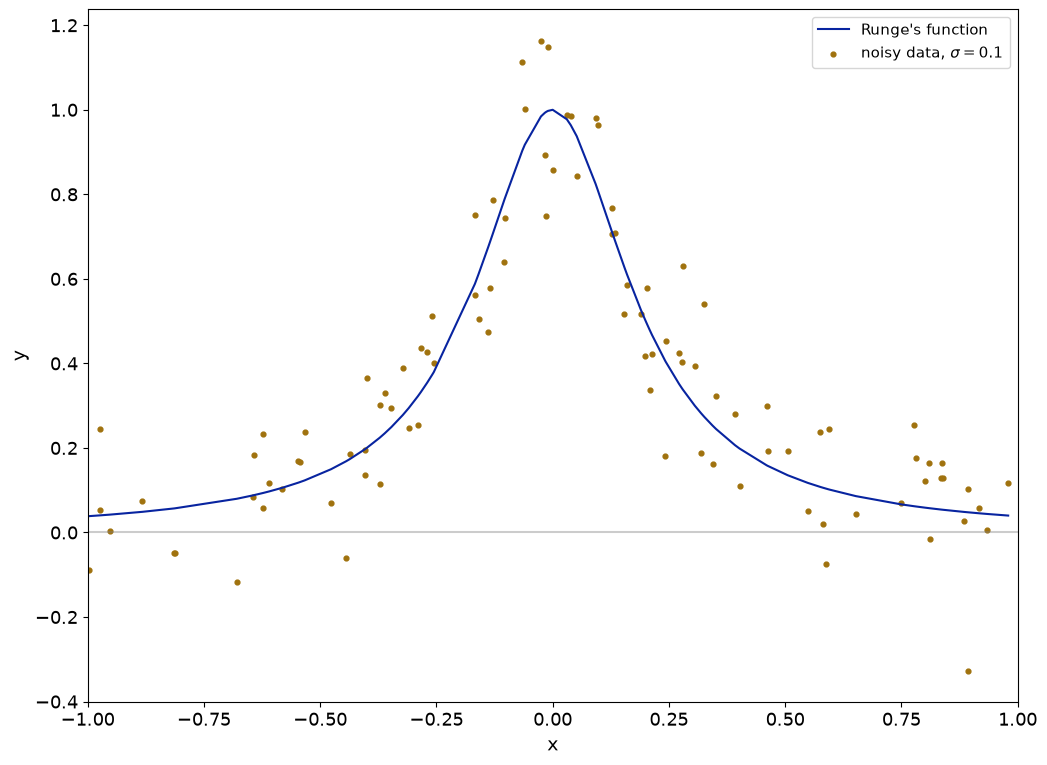

In [2]:
# The data of project 1, as a starting point for part b)

rng = np.random.default_rng(2026)      # fix the seed for reproducible results
n = 100
x = np.sort(rng.uniform(-1.0, 1.0, n))
sigma = 0.1
y = runge(x) + rng.normal(0.0, sigma, n)

# For the network the input is the raw x (one feature), samples in rows
X = x.reshape(-1, 1)
print(X.shape, y.shape)

plt.figure(figsize=(12, 9))
plt.plot(x, runge(x), color="#0824A0", label="Runge's function")
plt.scatter(x, y, s=12, color="#A0720E", label=rf"noisy data, $\sigma={sigma}$")
plt.xlabel("x", fontsize=label_fontsize); plt.ylabel("y", fontsize=label_fontsize); plt.legend(frameon=False, fontsize=legend_fontsize)
plt.xlim(-1,1)
plt.plot([-1,1], [0,0], color='grey', linestyle='-', alpha=0.4)
plt.legend(fontsize=legend_fontsize)
plt.tick_params(axis="both", which="major", labelsize=tick_fontsize)
plt.show()

In [3]:
#TEST on the functions above:
inputs = np.random.rand(1000, 4)

layers_b = create_layers_batch(4, [6, 5, 3])
layers_single = [(W.T, b) for W, b in layers_b]
out_batch = feed_forward_batch(inputs, layers_b, [ReLU, ReLU, sigmoid])
out_single = feed_forward(inputs[0], layers_single, [ReLU, ReLU, sigmoid])
print(out_batch.shape)
print("max difference on sample 0:", np.max(np.abs(out_batch[0] - out_single)))

#Testing the code with jax, both for single input and batch input
network_input_size = 2
layer_output_sizes = [3, 4]
activation_funcs = [sigmoid, ReLU]
activation_ders = [sigmoid_der, ReLU_der]

layers = create_layers(network_input_size, layer_output_sizes)

xx = np.random.rand(network_input_size)
target = np.random.rand(4)

layer_grads = backpropagation(xx, layers, activation_funcs, target, activation_ders)

cost_grad = jax.grad(cost, argnums=0)
layer_grads_jax = cost_grad(layers, xx, [sigmoid, ReLU], target)

# checking that the functions above agree with jax to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(layer_grads, layer_grads_jax) ])

inputs = np.random.rand(10, 2)
targets = np.random.rand(10, 4)
layers_b = create_layers_batch(2, [3, 4])

g_hand = backpropagation_batch(inputs, layers_b, activation_funcs, targets, activation_ders)
g_jax = jax.grad(cost_batch, argnums=0)(layers_b, inputs, activation_funcs, targets)

for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax):
    print("dW", dW.shape, np.allclose(dW, dW_j), "   db", db.shape, np.allclose(db, db_j))

(1000, 3)
max difference on sample 0: 5.551115123125783e-17
[(True, True), (True, True)]
dW (2, 3) True    db (3,) True
dW (3, 4) True    db (4,) True


[(True, True), (True, True)]
noise level based on the test data: 0.0096  (sigma^2 = 0.010000000000000002)
epoch   GD 50x1: cost  test diff     GD 100x2: cost  test diff
    1        0.76   0.636                0.19   0.157
    2        0.72   0.605                0.18   0.151
    5        0.63   0.524                0.16   0.138
   10        0.50   0.418                0.13   0.128
   20        0.33   0.281                0.11   0.127
   50        0.14   0.154                0.10   0.139
  100        0.10   0.146                0.10   0.142
  200        0.10   0.150                0.10   0.142
  500        0.09   0.145                0.10   0.141
 1000        0.09   0.143                0.09   0.140
GD 50x1, 1000 epochs      train cost 0.092   test cost 0.143
GD 100x2, 1000 epochs     train cost 0.094   test cost 0.140


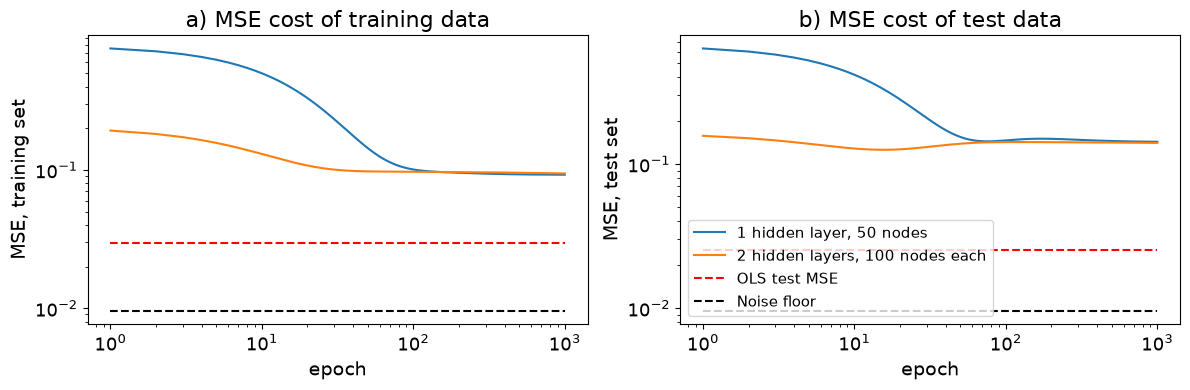

MSE train OLS: 0.029506814559850648
MSE test OLS: 0.025490471098851625


In [4]:
# Preapring data for training and testing
x_tr, x_te, y_tr, y_te = prepare_data(x,y)

#Getting the target values from closed form solution of OLS to compare with the neural network
prediction_OLS = OLS_regression(x_te, y_te)

#Set up activation functions and their derivatives for the network, as well as initialising the weights and biases
layers0, activation_funcs, activation_ders = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)

#Testing with JAX:
g_hand = backpropagation_batch(x_tr, layers0, activation_funcs, y_tr, activation_ders)
g_jax = jax.grad(cost_batch, argnums=0)(layers0, x_tr, activation_funcs, y_tr)

# checking that the functions above agree with JAX to machine precision
print([ (np.allclose(dW, dW_j), np.allclose(db, db_j))
        for (dW, db), (dW_j, db_j) in zip(g_hand, g_jax) ])

# Getting the noise floor on the test points
_, xtest, _, ytest = train_test_split(x, y, test_size=0.2, random_state=2026)
noise_floor = np.mean((ytest - runge(xtest)) ** 2)
print(f"noise level based on the test data: {noise_floor:.4f}  (sigma^2 = {sigma**2})")

#Compare the NN with 50 and 100 nodes and one and two hidden layers, with the closed form solution of OLS regression
layers_50, activation_funcs_50, activation_ders_50 = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)
layers_50,  hist_50, prediction_50  = train(layers_50, x_tr, y_tr, x_te, y_te, step="plain", act=activation_funcs_50, act_der=activation_ders_50, gamma=0.001, epochs=1000)

layers_100, activation_funcs_100, activation_ders_100 = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[100,100], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)
layers_100,  hist_100, prediction_100  = train(layers_100, x_tr, y_tr, x_te, y_te, step="plain", act=activation_funcs_100, act_der=activation_ders_100, gamma=0.001, epochs=1000)

print("epoch   GD 50x1: cost  test diff     GD 100x2: cost  test diff")
for e in [1, 2, 5, 10, 20, 50, 100, 200, 500, 1000]:
    g = hist_50[e - 1]
    s = hist_100[e - 1] if e <= len(hist_100) else None
    print("%5d     %7.2f   %.3f      " % (e, g[1], g[2])
          + ("       %7.2f   %.3f" % (s[1], s[2]) if s is not None else ""))

for name, L in [("GD 50x1, 1000 epochs", layers_50), ("GD 100x2, 1000 epochs", layers_100)]:
    print("%-25s train cost %.3f   test cost %.3f"
          % (name,  float(cost_batch(L, x_tr, activation_funcs_50 if L is layers_50 else activation_funcs_100, y_tr)),
             float(cost_batch(L, x_te, activation_funcs_50 if L is layers_50 else activation_funcs_100, y_te))))

#Plotting the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.semilogy(hist_50[:, 0], hist_50[:, 1], label="1 hidden layer, 50 nodes")
ax1.semilogy(hist_100[:, 0], hist_100[:, 1], label="2 hidden layers, 100 nodes each")
ax1.hlines(MSE(OLS_regression(x_tr, y_tr),y_tr), xmin=hist_50[0, 0], xmax=hist_50[-1, 0], colors='r', linestyles='dashed', label="OLS train MSE")
ax1.hlines(noise_floor, xmin=hist_50[0, 0], xmax=hist_50[-1, 0], colors='k', linestyles='dashed', label="Noise floor")

ax1.set_xlabel("epoch", fontsize=label_fontsize); ax1.set_ylabel("MSE, training set", fontsize=label_fontsize); ax1.set_xscale("log")#; ax1.set_yscale("log")
ax1.set_title("a) MSE cost of training data", fontsize=title_fontsize)
ax1.tick_params(axis='both', which='major', labelsize=tick_fontsize)
ax2.semilogy(hist_50[:, 0], hist_50[:, 2], label="1 hidden layer, 50 nodes")
ax2.semilogy(hist_100[:, 0], hist_100[:, 2], label="2 hidden layers, 100 nodes each")
ax2.hlines(MSE(OLS_regression(x_te, y_te),y_te), xmin=hist_50[0, 0], xmax=hist_50[-1, 0], colors='r', linestyles='dashed', label="OLS test MSE")
ax2.hlines(noise_floor, xmin=hist_50[0, 0], xmax=hist_50[-1, 0], colors='k', linestyles='dashed', label="Noise floor")
ax2.set_xlabel("epoch", fontsize=label_fontsize); ax2.set_ylabel("MSE, test set", fontsize=label_fontsize); ax2.set_xscale("log")
ax2.set_title("b) MSE cost of test data",fontsize=title_fontsize)
ax2.tick_params(axis='both', which='major', labelsize=tick_fontsize)
ax2.legend(fontsize=legend_fontsize,loc="best")

# fig.suptitle("Comparison of hidden layers and nodes")
plt.tight_layout()
plt.savefig("./figures/NN_50x1_100x2.png", dpi=500)
plt.show()

print("MSE train OLS:", MSE(OLS_regression(x_tr, y_tr),y_tr))
print("MSE test OLS:", MSE(OLS_regression(x_te, y_te),y_te))

<>:32: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:32: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
C:\Users\lukasjm\AppData\Local\Temp\ipykernel_28268\928576987.py:32: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
  ax.add_patch(plt.Rectangle((gammas.index((np.array(gammas)[within[0]])[0]) - 0.5, np.nanmin(grid_gammas[name])-8e-3), 1, 2e-2, fill=False, edgecolor="black", lw=3, linestyle="--",zorder=2,label="min $\gamma$ within 1 se"))


CV MSE with learning rate 0.0001: 0.1024
CV MSE with learning rate 0.0002: 0.0971
CV MSE with learning rate 0.0005: 0.0955
CV MSE with learning rate 0.001: 0.0955
CV MSE with learning rate 0.002: 0.0954
CV MSE with learning rate 0.005: 0.0949
CV MSE with learning rate 0.01: 0.0949
CV MSE with learning rate 0.02: 0.0971
CV MSE with learning rate 0.05: 0.0970
CV MSE with learning rate 0.1: 0.0350
CV MSE with learning rate 0.5: nan
CV MSE with learning rate 0.0001: 0.0909
CV MSE with learning rate 0.0002: 0.0872
CV MSE with learning rate 0.0005: 0.0734
CV MSE with learning rate 0.001: 0.0453
CV MSE with learning rate 0.002: 0.0303
CV MSE with learning rate 0.005: 0.0292
CV MSE with learning rate 0.01: 0.0323
CV MSE with learning rate 0.02: 0.0352
CV MSE with learning rate 0.05: 0.0364
CV MSE with learning rate 0.1: 0.0401
CV MSE with learning rate 0.5: 0.1762
CV MSE with learning rate 0.0001: 0.0924
CV MSE with learning rate 0.0002: 0.0907
CV MSE with learning rate 0.0005: 0.0830
CV MSE w

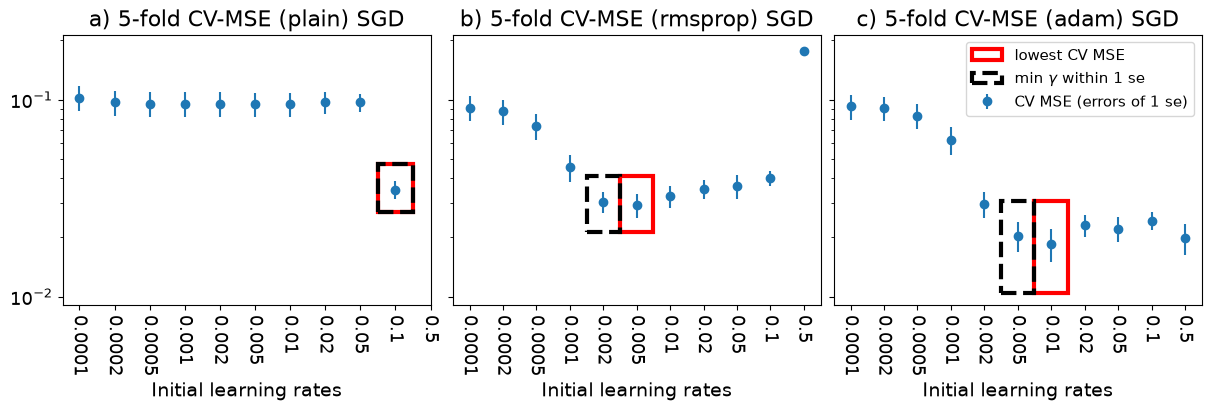

In [5]:
# Cross-validation to find the best learning rate for each of the three different SGD methods, based on the CV MSE

gammas = [0.0001,0.0002,0.0005,0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1, 0.5]

#Looping over different gammas for the three different SGD methods, to find the best learning rate for each method, based on the CV MSE
grid_gammas = {}
grid_se = {}
for name in ["plain","rmsprop","adam"]:
    score_mean = []
    score_se = []
    for gamma in gammas:

        mean, se = cv_mse_nopen(x_tr, y_tr, 50, 1, gamma, activation=sigmoid,activation_der=sigmoid_der,step=name)
        score_mean.append(mean)
        score_se.append(se)
        print(f"CV MSE with learning rate {gamma}: {mean:.4f}")
    
    grid_gammas[name], grid_se[name] = np.array(score_mean).reshape(1, len(gammas)), np.array(score_se).reshape(1, len(gammas))  
inds = ["a", "b", "c"]
eb_colors = []
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True,sharey=True)
for ax, name, ind in zip(axes, ["plain", "rmsprop", "adam"], inds):

    markers,_,lines = ax.errorbar(np.arange(len(gammas)), grid_gammas[name][0], yerr = grid_se[name], fmt='o',label="CV MSE (errors of 1 se)")
    i_best = np.unravel_index(np.nanargmin(grid_gammas[name]), grid_gammas[name].shape)
    within = grid_gammas[name] <= grid_gammas[name][i_best] + grid_se[name][i_best]
        
    print("Learning rates that achieve CV MSE within 1 standard error of the best:", np.array(gammas)[within[0]], f"({name})")
    ax.add_patch(plt.Rectangle((i_best[1] - 0.5, np.nanmin(grid_gammas[name])-8e-3), 1, 2e-2, fill=False, edgecolor="red", lw=3,zorder=1,label="lowest CV MSE")) 

    print("Minimum learning rate within 1 standard error:", (np.array(gammas)[within[0]])[0], f"({name})")
    ax.add_patch(plt.Rectangle((gammas.index((np.array(gammas)[within[0]])[0]) - 0.5, np.nanmin(grid_gammas[name])-8e-3), 1, 2e-2, fill=False, edgecolor="black", lw=3, linestyle="--",zorder=2,label="min $\gamma$ within 1 se")) 
        
    ax.set_yscale("log")
    
    ax.set_xticks(np.arange(len(gammas)))
    ax.set_xticklabels(gammas,rotation=270)
    ax.set_xlabel("Initial learning rates", fontsize=label_fontsize)
    ax.set_title(f"{ind}) 5-fold CV-MSE ({name}) SGD", fontsize=title_fontsize)
    ax.tick_params(axis='both', which='both', labelsize=tick_fontsize)
    
axes[2].legend(fontsize=legend_fontsize,loc="upper right")
    
# fig.suptitle("5-fold CV MSE",fontsize=title_fontsize)
plt.savefig("./figures/partb_gammas.png", dpi=500)
plt.show()

epoch   GD: cost  test diff     SGD+adam: cost  test diff    SGD+rmsprop: cost  test diff
    1      175.79   173.879                0.10   0.143          0.10   0.128
    2        0.17   0.295                0.16   0.281          0.10   0.164
    5        0.09   0.134                0.10   0.122          0.09   0.136
   10        0.13   0.221                0.09   0.134          0.10   0.166
   20        0.08   0.096                0.08   0.119          0.08   0.113
   50        0.04   0.066                0.04   0.062          0.06   0.094
  100        0.03   0.042                0.02   0.024          0.03   0.044
  200        0.03   0.031                0.02   0.015          0.02   0.025
GD, 1000 epochs           train cost 0.026   test cost 0.031
SGD+adam, 200 epochs      train cost 0.016   test cost 0.015
SGD+rmsprop, 200 epochs   train cost 0.022   test cost 0.025


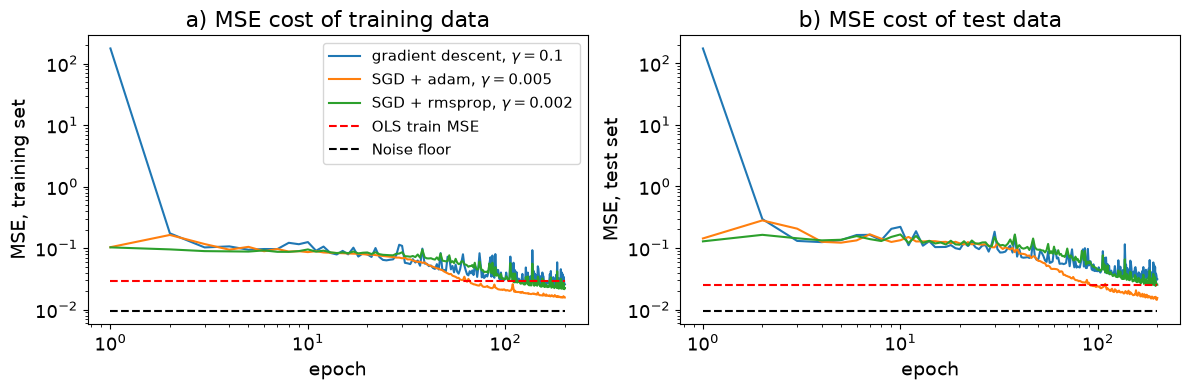

In [6]:
#Comparing plain GD with SGD Adam and RMSprop, with 1 hidden layer and 50 nodes

#Set up activation functions and their derivatives for the network, as well as initialising the weights and biases
layers0, activation_funcs, activation_ders = setup_NN(X.shape, y_tr.shape, design_hidden=[50], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)

#Train the datasets with different optimiser steps
layers_gd,  hist_gd, prediction_gd  = train(layers0, x_tr, y_tr, x_te, y_te, step="plain", act=activation_funcs, act_der=activation_ders, gamma=0.1, epochs=200,batch_size=15)
layers_adam, hist_adam, prediction_adam = train(layers0, x_tr, y_tr, x_te, y_te, step="adam", act=activation_funcs, act_der=activation_ders, gamma=0.005,  epochs=200, batch_size=15)
layers_rmsprop, hist_rmsprop, prediction_rmsprop = train(layers0, x_tr, y_tr, x_te, y_te, step="rmsprop", act=activation_funcs, act_der=activation_ders, gamma=0.002,  epochs=200, batch_size=15)

print("epoch   GD: cost  test diff     SGD+adam: cost  test diff    SGD+rmsprop: cost  test diff")
for e in [1, 2, 5, 10, 20, 50, 100, 200]:
    g = hist_gd[e - 1]
    a = hist_adam[e - 1] if e <= len(hist_adam) else None
    r = hist_rmsprop[e - 1] if e <= len(hist_rmsprop) else None
    print("%5d     %7.2f   %.3f      " % (e, g[1], g[2])
          + ("       %7.2f   %.3f" % (a[1], a[2]) if a is not None else "")
          + ("       %7.2f   %.3f" % (r[1], r[2]) if r is not None else ""))

for name, L in [("GD, 1000 epochs", layers_gd), ("SGD+adam, 200 epochs", layers_adam), ("SGD+rmsprop, 200 epochs", layers_rmsprop)]:
    print("%-25s train cost %.3f   test cost %.3f"
          % (name,  float(cost_batch(L, x_tr, activation_funcs, y_tr)),
             float(cost_batch(L, x_te, activation_funcs, y_te))))
    
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(hist_gd[:, 0], hist_gd[:, 1], label="gradient descent, $\\gamma=0.1$")
ax1.plot(hist_adam[:, 0], hist_adam[:, 1], label="SGD + adam, $\\gamma=0.005$")
ax1.plot(hist_rmsprop[:, 0], hist_rmsprop[:, 1], label="SGD + rmsprop, $\\gamma=0.002$")
ax1.hlines(MSE(OLS_regression(x_tr, y_tr),y_tr), xmin=hist_gd[0, 0], xmax=hist_gd[-1, 0], colors='r', linestyles='dashed', label="OLS train MSE")
ax1.hlines(noise_floor, xmin=hist_gd[0, 0], xmax=hist_gd[-1, 0], colors='k', linestyles='dashed', label="Noise floor")
ax1.set_xlabel("epoch", fontsize=label_fontsize); ax1.set_ylabel("MSE, training set", fontsize=label_fontsize); ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.legend(fontsize=legend_fontsize)
ax1.set_title("a) MSE cost of training data", fontsize=title_fontsize)
ax1.tick_params(axis='both', which='both', labelsize=tick_fontsize)

ax2.semilogy(hist_gd[:, 0], hist_gd[:, 2])
ax2.semilogy(hist_adam[:, 0], hist_adam[:, 2])
ax2.semilogy(hist_rmsprop[:, 0], hist_rmsprop[:, 2])
ax2.hlines(MSE(OLS_regression(x_te, y_te),y_te), xmin=hist_gd[0, 0], xmax=hist_gd[-1, 0], colors='r', linestyles='dashed', label="OLS test MSE")
ax2.hlines(noise_floor, xmin=hist_gd[0, 0], xmax=hist_gd[-1, 0], colors='k', linestyles='dashed', label="Noise floor")
ax2.set_xlabel("epoch", fontsize=label_fontsize); ax2.set_ylabel("MSE, test set", fontsize=label_fontsize); ax2.set_xscale("log")#; ax2.set_ylim(0, 0.4)
ax2.set_title("b) MSE cost of test data", fontsize=title_fontsize)
ax2.tick_params(axis='both', which='both', labelsize=tick_fontsize)

# fig.suptitle("Skill of different optimiser methods", fontsize=title_fontsize)
plt.tight_layout()
plt.savefig("./figures/NN_optimiser_comparison.png", dpi=500)
plt.show()

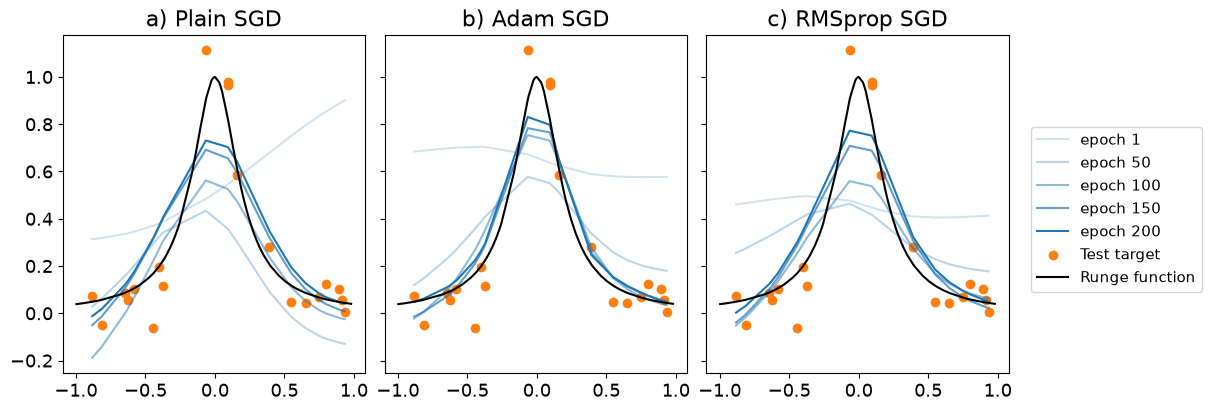

In [7]:
#Getting the raw data to plot with the Runge function
x_tr_raw, x_te_raw, _, _ = train_test_split(x, y, test_size=0.2, random_state=2026)

order = np.argsort(x_te_raw)

fig, ax = plt.subplots(1,3, figsize=(12, 4),sharey=True, constrained_layout=True)
ax[0].plot(x_te_raw[order], prediction_gd[1][order, 0],  label="epoch 1",color="tab:blue",alpha=0.2)
ax[0].plot(x_te_raw[order], prediction_gd[50][order, 0],  label="epoch 50",color="tab:blue",alpha=0.3)
ax[0].plot(x_te_raw[order], prediction_gd[100][order, 0],  label="epoch 100",color="tab:blue",alpha=0.5)
ax[0].plot(x_te_raw[order], prediction_gd[150][order, 0],  label="epoch 150",color="tab:blue",alpha=0.7)
ax[0].plot(x_te_raw[order], prediction_gd[-1][order, 0],  label="epoch 200",color="tab:blue",alpha=1)
ax[0].scatter(x_te_raw[order], y_te[order],  label="Test target",color="tab:orange",alpha=1)
ax[0].plot(x, runge(x), "k", label="Runge function")
ax[0].set_title("a) Plain SGD",fontsize=title_fontsize)
ax[0].tick_params(axis='both', which='both', labelsize=tick_fontsize)

ax[1].plot(x_te_raw[order], prediction_adam[1][order, 0],  label="epoch 1",color="tab:blue",alpha=0.2)
ax[1].plot(x_te_raw[order], prediction_adam[50][order, 0],  label="epoch 50",color="tab:blue",alpha=0.3)
ax[1].plot(x_te_raw[order], prediction_adam[100][order, 0],  label="epoch 100",color="tab:blue",alpha=0.5)
ax[1].plot(x_te_raw[order], prediction_adam[150][order, 0],  label="epoch 150",color="tab:blue",alpha=0.7)
ax[1].plot(x_te_raw[order], prediction_adam[-1][order, 0],  label="epoch 200",color="tab:blue",alpha=1)
ax[1].scatter(x_te_raw[order], y_te[order],  label="Test target",color="tab:orange",alpha=1)

ax[1].plot(x, runge(x), "k", label="Runge function")
ax[1].set_title("b) Adam SGD",fontsize=title_fontsize)
ax[1].tick_params(axis='both', which='both', labelsize=tick_fontsize)

ax[2].plot(x_te_raw[order], prediction_rmsprop[1][order, 0],  label="epoch 1",color="tab:blue",alpha=0.2)
ax[2].plot(x_te_raw[order], prediction_rmsprop[50][order, 0],  label="epoch 50",color="tab:blue",alpha=0.3)
ax[2].plot(x_te_raw[order], prediction_rmsprop[100][order, 0],  label="epoch 100",color="tab:blue",alpha=0.5)
ax[2].plot(x_te_raw[order], prediction_rmsprop[150][order, 0],  label="epoch 150",color="tab:blue",alpha=0.7)
ax[2].plot(x_te_raw[order], prediction_rmsprop[-1][order, 0],  label="epoch 200",color="tab:blue",alpha=1)
ax[2].scatter(x_te_raw[order], y_te[order],  label="Test target",color="tab:orange",alpha=1)

ax[2].plot(x, runge(x), "k", label="Runge function")
ax[2].set_title("c) RMSprop SGD",fontsize=title_fontsize)
ax[2].legend(bbox_to_anchor=(1.05, 0.75),fontsize=legend_fontsize)
ax[2].tick_params(axis='both', which='both', labelsize=tick_fontsize)

plt.savefig("./figures/optimiser_predict_comparison.png", dpi=500)
plt.show()

### Part c): Testing different activation functions and depths of the neural network

CV MSE for 1 hidden layers and 10 nodes per layer with sigmoid: 0.0233
CV MSE for 2 hidden layers and 10 nodes per layer with sigmoid: 0.0194
CV MSE for 3 hidden layers and 10 nodes per layer with sigmoid: 0.0210
CV MSE for 4 hidden layers and 10 nodes per layer with sigmoid: 0.0276
CV MSE for 1 hidden layers and 50 nodes per layer with sigmoid: 0.0204
CV MSE for 2 hidden layers and 50 nodes per layer with sigmoid: 0.0180
CV MSE for 3 hidden layers and 50 nodes per layer with sigmoid: 0.0179
CV MSE for 4 hidden layers and 50 nodes per layer with sigmoid: 0.0174
CV MSE for 1 hidden layers and 100 nodes per layer with sigmoid: 0.0210
CV MSE for 2 hidden layers and 100 nodes per layer with sigmoid: 0.0177
CV MSE for 3 hidden layers and 100 nodes per layer with sigmoid: 0.0181
CV MSE for 4 hidden layers and 100 nodes per layer with sigmoid: 0.0183
CV MSE for 1 hidden layers and 500 nodes per layer with sigmoid: 0.0341
CV MSE for 2 hidden layers and 500 nodes per layer with sigmoid: 0.0174


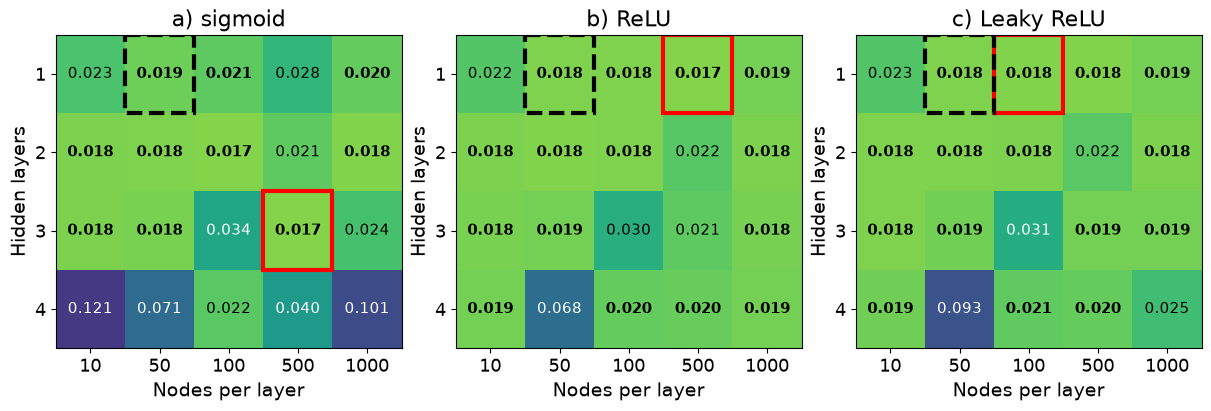

In [8]:
nlayers = [1,2,3,4]
nodes = [10, 50, 100,500,1000]

grid_layernodes = {}
grid_se = {}
for name, act, act_der in [("sigmoid", sigmoid, sigmoid_der),("ReLU", ReLU, ReLU_der), ("Leaky ReLU", leaky_ReLU, leaky_ReLU_der)]:
    score_mean = []
    score_se = []
    for node in nodes:
        for nlayer in nlayers:
            mean, se = cv_mse_nopen(x_tr, y_tr, node, nlayer, 0.005, activation=act,activation_der=act_der)
            score_mean.append(mean)
            score_se.append(se)
            print(f"CV MSE for {nlayer} hidden layers and {node} nodes per layer with {name}: {mean:.4f}")
    
    grid_layernodes[name], grid_se[name] = np.array(score_mean).reshape(len(nlayers), len(nodes)), np.array(score_se).reshape(len(nlayers), len(nodes))  

fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, name, ind in zip(axes, ["sigmoid", "ReLU", "Leaky ReLU"], ["a)", "b)", "c)"]):

    heatmap_nopen(ax, grid_layernodes[name], nlayers, [n for n in nodes], f"{ind} {name}", r"Hidden layers",r"Nodes per layer", grid_se=grid_se[name],
                   label_fontsize=label_fontsize, title_fontsize=title_fontsize, tick_fontsize=tick_fontsize, annot_fontsize=legend_fontsize)
    ax.add_patch(plt.Rectangle((1 - 0.5, 0 - 0.5), 1, 1, fill=False, edgecolor="black", lw=3, linestyle="--"))   # choice of parameters due to 1se rule

# fig.suptitle("5-fold CV MSE, Adam SGD")
plt.savefig("./figures/partc_nlayers_nodes.png", dpi=500)
plt.show()

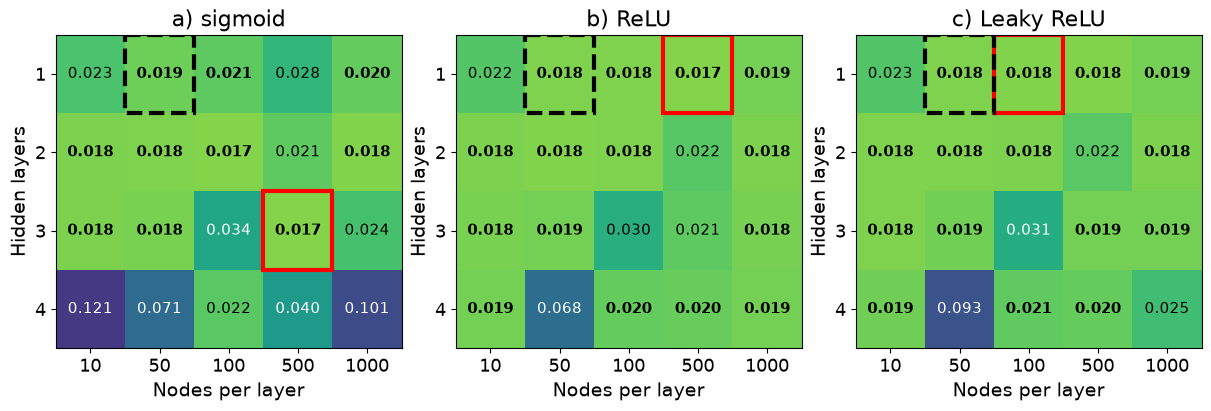

In [9]:
#Same figure as above
fig, axes = plt.subplots(1, 3, figsize=(12, 4), constrained_layout=True)
for ax, name, ind in zip(axes, ["sigmoid", "ReLU", "Leaky ReLU"], ["a)", "b)", "c)"]):

    heatmap_nopen(ax, grid_layernodes[name], nlayers, [n for n in nodes], f"{ind} {name}", r"Hidden layers",r"Nodes per layer", grid_se=grid_se[name],
                   label_fontsize=label_fontsize, title_fontsize=title_fontsize, tick_fontsize=tick_fontsize, annot_fontsize=legend_fontsize)
    ax.add_patch(plt.Rectangle((1 - 0.5, 0 - 0.5), 1, 1, fill=False, edgecolor="black", lw=3, linestyle="--"))   # choice of parameters due to 1se rule

# fig.suptitle("5-fold CV MSE, Adam SGD")
#plt.savefig("./figures/partc_nlayers_nodes.png", dpi=500)
plt.show()

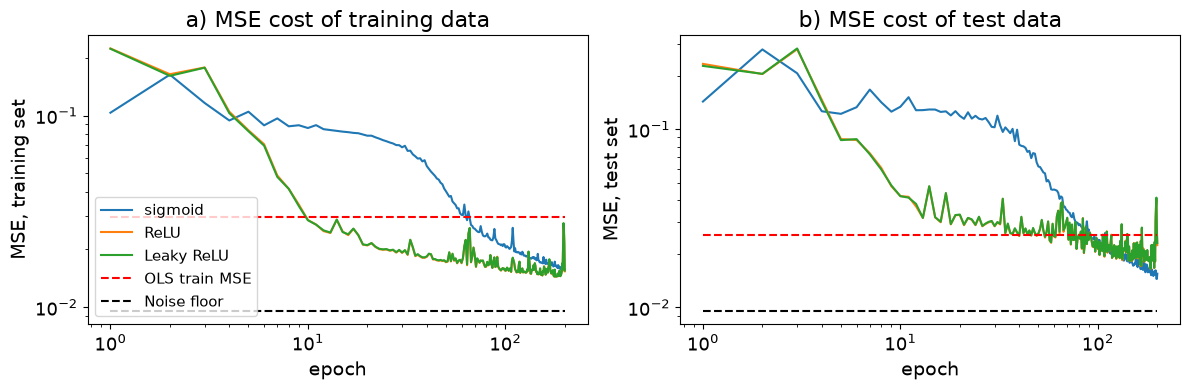

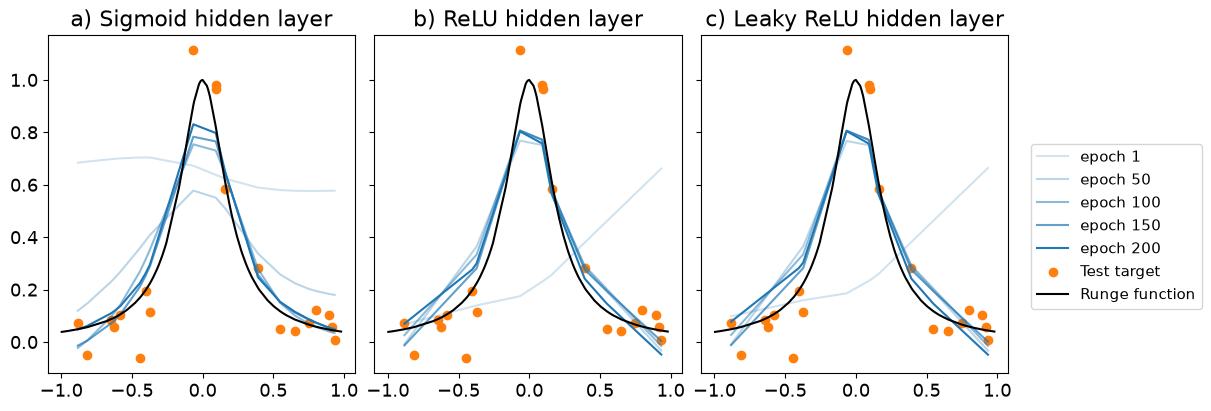

In [10]:
#doing the training with the best parameters found above, with 1 hidden layer and 50 nodes (based on the 1 standard error rule)

#sigmoid as hidden layer
layers0, activation_funcs, activation_ders = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=sigmoid, activation_ders=sigmoid_der, activation_output=identity, activation_output_der=identity_der)
layers_sig, hist_sig,prediction_sig = train(layers0, x_tr, y_tr, x_te, y_te, step="adam",act=activation_funcs,act_der=activation_ders, gamma=0.005,  epochs=200, batch_size=15)

#ReLU as hidden layer
layers0, activation_funcs, activation_ders = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=ReLU, activation_ders=ReLU_der, activation_output=identity, activation_output_der=identity_der)
layers_relu, hist_relu,prediction_relu = train(layers0, x_tr, y_tr, x_te, y_te, step="adam",act=activation_funcs,act_der=activation_ders, gamma=0.005,  epochs=200, batch_size=15)

#Leaky ReLU as hidden layer
layers0, activation_funcs, activation_ders = setup_NN(x_tr.shape, y_tr.shape, design_hidden=[50], activation_funcs=leaky_ReLU, activation_ders=leaky_ReLU_der, activation_output=identity, activation_output_der=identity_der)
layers_lrelu, hist_lrelu,prediction_lrelu = train(layers0, x_tr, y_tr, x_te, y_te, step="adam",act=activation_funcs,act_der=activation_ders, gamma=0.005,  epochs=200, batch_size=15)

#plotting the results
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.semilogy(hist_sig[:, 0], hist_sig[:, 1], label="sigmoid")
ax1.semilogy(hist_relu[:, 0], hist_relu[:, 1], label="ReLU")
ax1.semilogy(hist_lrelu[:, 0], hist_lrelu[:, 1], label="Leaky ReLU")
ax1.hlines(MSE(OLS_regression(x_tr, y_tr),y_tr), xmin=hist_sig[0, 0], xmax=hist_sig[-1, 0], colors='r', linestyles='dashed', label="OLS train MSE")
ax1.hlines(noise_floor, xmin=hist_sig[0, 0], xmax=hist_sig[-1, 0], colors='k', linestyles='dashed', label="Noise floor")

ax1.set_xlabel("epoch",fontsize=label_fontsize); ax1.set_ylabel("MSE, training set",fontsize=label_fontsize); ax1.set_xscale("log"); ax1.set_yscale("log"); ax1.legend(fontsize=legend_fontsize)
ax1.set_title("a) MSE cost of training data",fontsize=title_fontsize)
ax1.tick_params(axis='both', which='both', labelsize=tick_fontsize)
ax2.semilogy(hist_sig[:, 0], hist_sig[:, 2])
ax2.semilogy(hist_relu[:, 0], hist_relu[:, 2])
ax2.semilogy(hist_lrelu[:, 0], hist_lrelu[:, 2])
ax2.hlines(MSE(OLS_regression(x_te, y_te),y_te), xmin=hist_sig[0, 0], xmax=hist_sig[-1, 0], colors='r', linestyles='dashed', label="OLS test MSE")
ax2.hlines(noise_floor, xmin=hist_sig[0, 0], xmax=hist_sig[-1, 0], colors='k', linestyles='dashed', label="Noise floor")
ax2.set_xlabel("epoch",fontsize=label_fontsize); ax2.set_ylabel("MSE, test set",fontsize=label_fontsize); ax2.set_xscale("log")
ax2.set_title("b) MSE cost of test data",fontsize=title_fontsize)
ax2.tick_params(axis='both', which='both', labelsize=tick_fontsize)
# fig.suptitle("Different hidden layer activation functions",fontsize=title_fontsize)
plt.tight_layout()
plt.savefig("./figures/NN_activation_comparison.png", dpi=500)
plt.show()

fig, ax = plt.subplots(1,3, figsize=(12, 4),sharey=True, constrained_layout=True)
ax[0].plot(x_te_raw[order], prediction_sig[1][order, 0],  label="epoch 1",color="tab:blue",alpha=0.2)
ax[0].plot(x_te_raw[order], prediction_sig[50][order, 0],  label="epoch 50",color="tab:blue",alpha=0.3)
ax[0].plot(x_te_raw[order], prediction_sig[100][order, 0],  label="epoch 100",color="tab:blue",alpha=0.5)
ax[0].plot(x_te_raw[order], prediction_sig[150][order, 0],  label="epoch 150",color="tab:blue",alpha=0.7)
ax[0].plot(x_te_raw[order], prediction_sig[-1][order, 0],  label="epoch 200",color="tab:blue",alpha=1)
ax[0].scatter(x_te_raw[order], y_te[order],  label="Test target",color="tab:orange",alpha=1)
ax[0].plot(x, runge(x), "k", label="Runge function")
ax[0].set_title("a) Sigmoid hidden layer",fontsize=title_fontsize)
ax[0].tick_params(axis='both', which='both', labelsize=tick_fontsize)

ax[1].plot(x_te_raw[order], prediction_relu[1][order, 0],  label="epoch 1",color="tab:blue",alpha=0.2)
ax[1].plot(x_te_raw[order], prediction_relu[50][order, 0],  label="epoch 50",color="tab:blue",alpha=0.3)
ax[1].plot(x_te_raw[order], prediction_relu[100][order, 0],  label="epoch 100",color="tab:blue",alpha=0.5)
ax[1].plot(x_te_raw[order], prediction_relu[150][order, 0],  label="epoch 150",color="tab:blue",alpha=0.7)
ax[1].plot(x_te_raw[order], prediction_relu[-1][order, 0],  label="epoch 200",color="tab:blue",alpha=1)
ax[1].scatter(x_te_raw[order], y_te[order],  label="Test target",color="tab:orange",alpha=1)
ax[1].tick_params(axis='both', which='both', labelsize=tick_fontsize)
ax[1].plot(x, runge(x), "k", label="Runge function")
ax[1].set_title("b) ReLU hidden layer",fontsize=title_fontsize)

ax[2].plot(x_te_raw[order], prediction_lrelu[1][order, 0],  label="epoch 1",color="tab:blue",alpha=0.2)
ax[2].plot(x_te_raw[order], prediction_lrelu[50][order, 0],  label="epoch 50",color="tab:blue",alpha=0.3)
ax[2].plot(x_te_raw[order], prediction_lrelu[100][order, 0],  label="epoch 100",color="tab:blue",alpha=0.5)
ax[2].plot(x_te_raw[order], prediction_lrelu[150][order, 0],  label="epoch 150",color="tab:blue",alpha=0.7)
ax[2].plot(x_te_raw[order], prediction_lrelu[-1][order, 0],  label="epoch 200",color="tab:blue",alpha=1)
ax[2].scatter(x_te_raw[order], y_te[order],  label="Test target",color="tab:orange",alpha=1)
ax[2].tick_params(axis='both', which='both', labelsize=tick_fontsize)
ax[2].plot(x, runge(x), "k", label="Runge function")
ax[2].set_title("c) Leaky ReLU hidden layer",fontsize=title_fontsize)
ax[2].legend(bbox_to_anchor=(1.05, 0.7),fontsize=legend_fontsize)
plt.savefig("./figures/predict_activation_comparison.png", dpi=500)
plt.show()

### Part d): Testing different norms

In [11]:
# Your code for part d) here
###################################
# add the L1 / L2 penalties to the network code of part b)
###################################

# same data, split and scaling as in part b)
x_tr, x_te, y_tr, y_te = prepare_data(x, y)

for norm in ["l2", "l1"]:
    print(f"norm = {norm}: max |JAX - backprop| = {check_gradient_jax(x_tr, y_tr, norm):.1e}")

norm = l2: max |JAX - backprop| = 5.6e-17
norm = l1: max |JAX - backprop| = 5.6e-17


In [12]:
###################################
# the benchmarks from project 1 (OLS, Ridge, Lasso on polynomial features)
###################################

warnings.filterwarnings("ignore", category=ConvergenceWarning)   # remove annoying warnings

# The same 80/20 split as the network, but with the raw x (the polynomial pipeline scales itself)
x_tr_raw, x_te_raw, y_tr_raw, y_te_raw = train_test_split(x, y, test_size=0.2, random_state=2026)
assert np.allclose(y_tr_raw, y_tr.ravel()) # check: same training points as the network

# 5-fold cross-validation on the TRAINING data only (the test set is not touched here).
# NB: these are the same folds that are used for the network below.
kfold = KFold(5, shuffle=True, random_state=2026)

degrees = list(range(1, 13)) # polynomial degrees as in project 1
poly_lams = np.logspace(-6, 0, 13) # lambda grid for Ridge and Lasso

baseline = {} # kind -> (cv mse, degree, lambda)
for kind in ["OLS", "Ridge", "Lasso"]:
    best = (np.inf, None, None)
    for d in degrees:
        for lam in ([0.0] if kind == "OLS" else poly_lams):
            err = poly_cv(kind, d, lam, x_tr_raw, y_tr_raw, kfold)
            if err < best[0]:
                best = (err, d, lam)
    baseline[kind] = best
    print(f"{kind:5s}: best CV-MSE = {best[0]:.4f} at degree {best[1]}" +
          ("" if kind == "OLS" else f", lambda = {best[2]:.1e}"))

# Refit the three winners on all 80 training points and evaluate on the 20 test points
baseline_models = {}
for kind, (cv_err, d, lam) in baseline.items():
    m = fit_poly(kind, d, lam, x_tr_raw, y_tr_raw)
    baseline_models[kind] = m
    train_mse = np.mean((y_tr_raw - m.predict(x_tr_raw.reshape(-1, 1))) ** 2)
    test_mse = np.mean((y_te_raw - m.predict(x_te_raw.reshape(-1, 1))) ** 2)
    baseline[kind] = (cv_err, d, lam, train_mse, test_mse)
    print(f"{kind:5s}: train MSE = {train_mse:.4f}, test MSE = {test_mse:.4f}")

# The best any model can do on these 20 test points is the noise in them:
noise_floor = np.mean((y_te_raw - runge(x_te_raw)) ** 2)
print(f"noise level on the test points (true Runge function vs data): {noise_floor:.4f}  (sigma^2 = {sigma**2})")

OLS  : best CV-MSE = 0.0266 at degree 8
Ridge: best CV-MSE = 0.0226 at degree 12, lambda = 3.2e-06
Lasso: best CV-MSE = 0.0259 at degree 9, lambda = 1.0e-04
OLS  : train MSE = 0.0173, test MSE = 0.0187
Ridge: train MSE = 0.0156, test MSE = 0.0221
Lasso: train MSE = 0.0172, test MSE = 0.0184
noise level on the test points (true Runge function vs data): 0.0096  (sigma^2 = 0.010000000000000002)


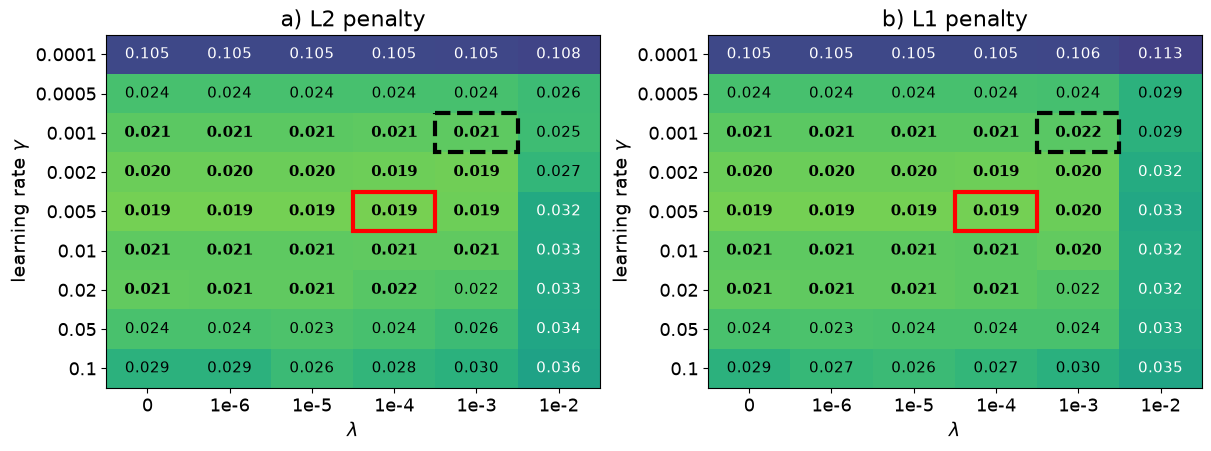

learning rate used from here on: gamma = 0.005


In [13]:
lam_grid = [0.0, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2] # lambda = 0 is the unregularised network
gamma_grid = [0.0001, 0.0005, 0.001, 0.002, 0.005, 0.01, 0.02, 0.05, 0.1] # learning rates for Adam
lam_labels = [lam_label(l) for l in lam_grid]
norms = ["l2", "l1"]

grid_gl, grid_gl_se = {}, {} # norm -> (len(gamma_grid) x len(lam_grid)) arrays: CV MSE and its standard error
for norm in norms:
    res = np.array([[cv_mse(x_tr, y_tr, [50], g, lam, norm) for lam in lam_grid] for g in gamma_grid]) # last axis: (mean, se)
    grid_gl[norm], grid_gl_se[norm] = res[..., 0], res[..., 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for ax, norm, name in zip(axes, norms, ["a) L2 penalty", "b) L1 penalty"]):
    heatmap_nopen(ax, grid_gl[norm], gamma_grid, lam_labels, name, r"learning rate $\gamma$", r"$\lambda$", grid_se=grid_gl_se[norm],
                   label_fontsize=label_fontsize, title_fontsize=title_fontsize, tick_fontsize=tick_fontsize, annot_fontsize=legend_fontsize)
# black dashed frame to choose best according to 1 se rule 
    ax.add_patch(plt.Rectangle((lam_grid.index(1e-3) - 0.5, gamma_grid.index(0.001) - 0.5), 1, 1, fill=False, edgecolor="black", lw=3, linestyle="--", clip_on=False))
# fig.suptitle("5-fold CV MSE, Adam, 1 hidden layer with 50 ReLU nodes (red = lowest, black = 1-se rule, bold = within 1 se)")
plt.savefig("./figures/partd_lambda_gamma.png", dpi=500)
plt.show()

# One learning rate for the rest of part d): the best one over both grids (all lambda)
best_gamma = min(((grid_gl[n][i, j], gamma_grid[i]) for n in norms
                  for i in range(len(gamma_grid)) for j in range(len(lam_grid))))[1]
print("learning rate used from here on: gamma =", best_gamma)

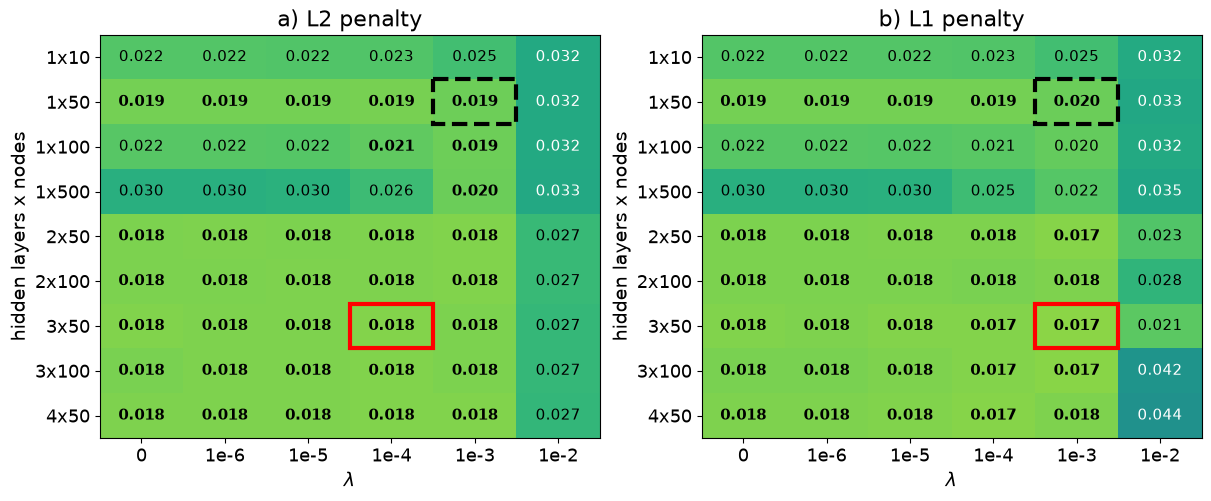

best l2  : hidden layers [50, 50, 50], lambda = 0.0001, CV MSE = 0.0175
best l1  : hidden layers [50, 50, 50], lambda = 0.001, CV MSE = 0.0168
best unpenalised: hidden layers [50, 50, 50], lambda = 0, CV MSE = 0.0177

architecture   CV MSE (lambda=0)   best L2: CV MSE (lambda)    best L1: CV MSE (lambda)
1x10           0.0224           0.0224 (1e-06)        0.0224 (1e-06)   
1x50           0.0187           0.0185 (1e-04)        0.0186 (1e-04)   
1x100          0.0218           0.0193 (1e-03)        0.0204 (1e-03)   
1x500          0.0303           0.0197 (1e-03)        0.0220 (1e-03)   
2x50           0.0180           0.0176 (1e-03)        0.0172 (1e-03)   
2x100          0.0180           0.0177 (1e-03)        0.0178 (1e-03)   
3x50           0.0177           0.0175 (1e-04)        0.0168 (1e-03)   
3x100          0.0184           0.0176 (1e-04)        0.0170 (1e-03)   
4x50           0.0179           0.0176 (1e-04)        0.0173 (1e-04)   


In [14]:
###################################
# lambda x network architecture (the learning rate is kept at its best value)
###################################
architectures = [[10], [50], [100], [500], [50, 50], [100, 100], [50, 50, 50], [100, 100, 100], [50, 50, 50, 50]]
arch_labels = [f"{len(a)}x{a[0]}" for a in architectures] # e.g. "2x50" = 2 hidden layers, 50 nodes

grid_al, grid_al_se = {}, {} # norm -> (architectures x lambdas): CV MSE and its standard error
for norm in norms:
    res = np.array([[cv_mse(x_tr, y_tr, a, best_gamma, lam, norm) for lam in lam_grid] for a in architectures])
    grid_al[norm], grid_al_se[norm] = res[..., 0], res[..., 1]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.9), constrained_layout=True)
for ax, norm, name in zip(axes, norms, ["a) L2 penalty", "b) L1 penalty"]):
    heatmap_nopen(ax, grid_al[norm], arch_labels, lam_labels, name, "hidden layers x nodes", r"$\lambda$", grid_se=grid_al_se[norm],
                   label_fontsize=label_fontsize, title_fontsize=title_fontsize, tick_fontsize=tick_fontsize, annot_fontsize=legend_fontsize)
# black dashed frame = the cell you choose (1-se rule): give its architecture label and its lambda
    ax.add_patch(plt.Rectangle((lam_grid.index(1e-3) - 0.5, arch_labels.index("1x50") - 0.5), 1, 1, fill=False, edgecolor="black", lw=3, linestyle="--", clip_on=False))
# fig.suptitle(rf"5-fold CV MSE, Adam, $\gamma$ = {best_gamma}, ReLU (red = lowest, black = 1-se rule, bold = within 1 se)")
plt.savefig("./figures/partd_lambda_architecture.png", dpi=500)
plt.show()

# Best settings: with the penalty (lambda > 0) for each norm, and without (lambda = 0) as reference
choice = {} # name -> (hidden, lambda, norm, cv mse)
for norm in norms:
    sub = grid_al[norm][:, 1:] # drop the lambda = 0 column
    i, j = np.unravel_index(np.argmin(sub), sub.shape)
    choice[norm] = (architectures[i], lam_grid[j + 1], norm, sub[i, j])
i0 = np.argmin(grid_al["l2"][:, 0]) # column lambda = 0 (same for L1 and L2)
choice["unpenalised"] = (architectures[i0], 0.0, "l2", grid_al["l2"][i0, 0]) # lambda = 0: the norm does not matter
for name, (hid, lam, norm, err) in choice.items():
    print(f"best {name:4s}: hidden layers {hid}, lambda = {lam:g}, CV MSE = {err:.4f}")

# Does the penalty help? Compare, for every architecture, lambda = 0 with the best lambda > 0
print("\narchitecture   CV MSE (lambda=0)   best L2: CV MSE (lambda)    best L1: CV MSE (lambda)")
for i, lab in enumerate(arch_labels):
    line = f"{lab:12s}   {grid_al['l2'][i, 0]:.4f}      "
    for norm in norms:
        j = np.argmin(grid_al[norm][i, 1:]) + 1
        line += f"     {grid_al[norm][i, j]:.4f} ({lam_grid[j]:.0e})   "
    print(line)


model                          settings                           train MSE  test MSE
OLS (polynomial)               degree 8                              0.0173    0.0187
Ridge (polynomial)             degree 12, lambda=3e-06               0.0156    0.0221
Lasso (polynomial)             degree 9, lambda=1e-04                0.0172    0.0184
NN, no penalty                 3x50, lambda=0, gamma=0.001           0.0135    0.0140
NN + L2                        3x50, lambda=0.0001, gamma=0.001      0.0137    0.0151
NN + L1                        3x50, lambda=0.001, gamma=0.001       0.0141    0.0176
NN 1x50, no penalty            1x50, lambda=0, gamma=0.001           0.0172    0.0261
NN 1x50 + L2                   1x50, lambda=0.001, gamma=0.001       0.0172    0.0257
NN 1x50 + L1                   1x50, lambda=0.001, gamma=0.001       0.0175    0.0263
noise level of test points                                                     0.0096


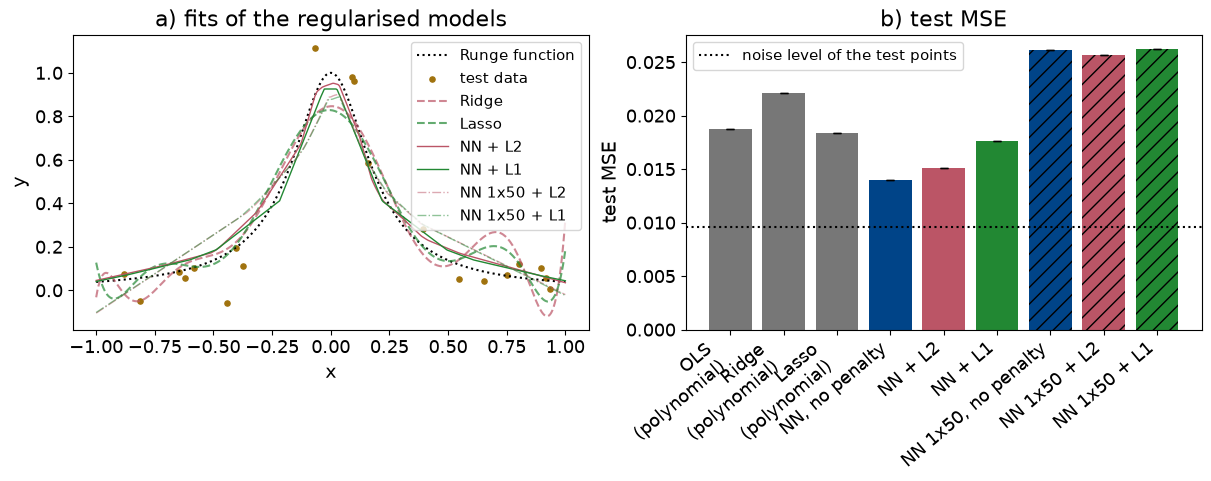

In [15]:
###################################
# final training, comparison with OLS / Ridge / Lasso
###################################
seeds = [2026]
# seeds = range(10) #for a mean +- spread over several runs (10 times slower)

# 1x50 network chosen with the 1-se rule, without penalty and with L2 / L1 (set your lambdas)
choice["unpenalised_1se"] = ([50], 0.0, "l2", None)
choice["l2_1se"] = ([50], 1e-3, "l2", None)
choice["l1_1se"] = ([50], 1e-3, "l1", None)

x_mean, x_std = x_tr_raw.mean(), x_tr_raw.std() # the same scaling as in prepare_data
xx = np.linspace(-1, 1, 400) # dense grid for plotting the fits
xx_std = ((xx - x_mean) / x_std).reshape(-1, 1)

final = {} # name -> dict with the results
for name, (hid, lam, norm, _) in choice.items():
    tr_err, te_err = [], []
    for seed in seeds:
        layers, act, der = build_net(hid, seed=seed)
        if '1se' in name:
            best_gamma = 0.001
        else:
            best_gamma = 0.005
        layers, hist = train_penalised(layers, x_tr, y_tr, x_te, y_te, "adam", act, der,
                                       best_gamma, 200, lam, norm, seed=seed)
        tr_err.append(hist[-1, 1]) # MSE after the last epoch
        te_err.append(hist[-1, 2])
        if seed == seeds[0]: # keep the fit of the first run for the plot
            curve = feed_forward_batch(xx_std, layers, act)[:, 0]
    final[name] = dict(train=np.mean(tr_err), test=np.mean(te_err), test_std=np.std(te_err), curve=curve)

### Table
print(f"\n{'model':30s} {'settings':34s} {'train MSE':>9s} {'test MSE':>9s}")
rows = []
for kind in ["OLS", "Ridge", "Lasso"]:
    cv_err, d, lam, tr_m, te_m = baseline[kind]
    s = f"degree {d}" + ("" if kind == "OLS" else f", lambda={lam:.0e}")
    rows.append((kind + " (polynomial)", s, tr_m, te_m, 0.0))
for name, label in [("unpenalised", "NN, no penalty"), ("l2", "NN + L2"), ("l1", "NN + L1"),
                    ("unpenalised_1se", "NN 1x50, no penalty"), ("l2_1se", "NN 1x50 + L2"), ("l1_1se", "NN 1x50 + L1")]:
    hid, lam, norm, _ = choice[name]
    s = f"{len(hid)}x{hid[0]}, lambda={lam:g}, gamma={best_gamma}"
    rows.append((label, s, final[name]["train"], final[name]["test"], final[name]["test_std"]))
for r in rows:
    spread = f" +- {r[4]:.4f}" if r[4] > 0 else "" # the spread only exists with several seeds
    print(f"{r[0]:30s} {r[1]:34s} {r[2]:9.4f} {r[3]:9.4f}{spread}")
print(f"{'noise level of test points':30s} {'':34s} {'':9s} {noise_floor:9.4f}")

### Figure: (a) fits of the regularised models, (b) test MSE of all models
fig, ax = plt.subplots(1, 2, figsize=(12, 4.7), constrained_layout=True)

ax[0].plot(xx, runge(xx), "k:", label="Runge function")
ax[0].scatter(x_te_raw, y_te_raw, s=14, color="#A0720E", label="test data")
ax[0].plot(xx, baseline_models["Ridge"].predict(xx.reshape(-1, 1)), color=RED, alpha=0.7, ls="--", label="Ridge")
ax[0].plot(xx, baseline_models["Lasso"].predict(xx.reshape(-1, 1)), color=GREEN, alpha=0.7, ls="--", label="Lasso")
ax[0].plot(xx, final["l2"]["curve"], color=RED, ls="-", lw=1, alpha=1, label="NN + L2")
ax[0].plot(xx, final["l1"]["curve"], color=GREEN, ls="-", lw=1, alpha=1, label="NN + L1")
ax[0].plot(xx, final["l2_1se"]["curve"], color=RED, ls="-.", lw=1, alpha=0.5, label="NN 1x50 + L2")
ax[0].plot(xx, final["l1_1se"]["curve"], color=GREEN, ls="-.", lw=1, alpha=0.5, label="NN 1x50 + L1")
ax[0].set_xlabel("x", fontsize=label_fontsize); ax[0].set_ylabel("y", fontsize=label_fontsize); ax[0].legend(fontsize=legend_fontsize)
ax[0].set_title("a) fits of the regularised models", fontsize=title_fontsize)
ax[0].tick_params(axis="both", which="major", labelsize=tick_fontsize)

labels = [r[0] for r in rows]
bars = ax[1].bar(range(len(rows)), [r[3] for r in rows], yerr=[r[4] for r in rows],
                 color=[GREY, GREY, GREY, BLUE, RED, GREEN, BLUE, RED, GREEN], capsize=3) 
for b in bars[6:]:
    b.set_hatch("//") # hatched = the 1x50 network chosen with the 1-se rule
ax[1].axhline(noise_floor, color="k", ls=":", label="noise level of the test points")
ax[1].set_xticks(range(len(rows)))
ax[1].set_xticklabels([l.replace(" (polynomial)", "\n(polynomial)") for l in labels], rotation=40, ha="right", fontsize=tick_fontsize)
ax[1].set_ylabel("test MSE", fontsize=label_fontsize); ax[1].legend(fontsize=legend_fontsize)
ax[1].set_title("b) test MSE", fontsize=title_fontsize)
ax[1].tick_params(axis="both", which="major", labelsize=tick_fontsize)
plt.savefig("./figures/partd_comparison.png", dpi=500)
plt.show()

### Part e): Classification analysis using neural networks

In [17]:
# Your code for part e) here
with np.load("mnist.npz") as data:
    X_train = data["x_train"]
    y_train = data["y_train"]
    X_test = data["x_test"]
    y_test = data["y_test"]

# Flatten each 28x28 image into 784 numbers
X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

# Scale pixel values from 0-255 to 0-1
X_train = X_train / 255.0
X_test = X_test / 255.0

In [18]:
# Split the original training data into training and validation sets
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=2026,
    stratify=y_train
)

# Convert the training labels into one-hot format
Y_fit = one_hot(y_fit)

print("Training images:", X_fit.shape)
print("Validation images:", X_val.shape)
print("Training labels:", Y_fit.shape)

Training images: (48000, 784)
Validation images: (12000, 784)
Training labels: (48000, 10)


In [19]:
    
# Define the network architecture
layers = init_layers_zero_bias([784, 32, 10], seed=2026)

# Choose activation functions
activation_funcs = [ReLU, softmax]
activation_ders = [ReLU_der]

# Train the network
layers, history = train_classifier(
    layers,
    X_fit,
    Y_fit,
    X_val,
    y_val,
    activation_funcs,
    activation_ders,
    gamma=0.001,
    epochs=15,
    batch_size=128,
    method="adam"
)

Epoch 1/15 | Training loss: 0.3080 | Validation loss: 0.3110 | Validation accuracy: 0.9128
Epoch 2/15 | Training loss: 0.2510 | Validation loss: 0.2638 | Validation accuracy: 0.9253
Epoch 3/15 | Training loss: 0.2126 | Validation loss: 0.2288 | Validation accuracy: 0.9343
Epoch 4/15 | Training loss: 0.1852 | Validation loss: 0.2036 | Validation accuracy: 0.9423
Epoch 5/15 | Training loss: 0.1679 | Validation loss: 0.1908 | Validation accuracy: 0.9458
Epoch 6/15 | Training loss: 0.1530 | Validation loss: 0.1789 | Validation accuracy: 0.9485
Epoch 7/15 | Training loss: 0.1368 | Validation loss: 0.1650 | Validation accuracy: 0.9520
Epoch 8/15 | Training loss: 0.1292 | Validation loss: 0.1586 | Validation accuracy: 0.9525
Epoch 9/15 | Training loss: 0.1192 | Validation loss: 0.1513 | Validation accuracy: 0.9547
Epoch 10/15 | Training loss: 0.1061 | Validation loss: 0.1418 | Validation accuracy: 0.9594
Epoch 11/15 | Training loss: 0.1005 | Validation loss: 0.1398 | Validation accuracy: 0.95

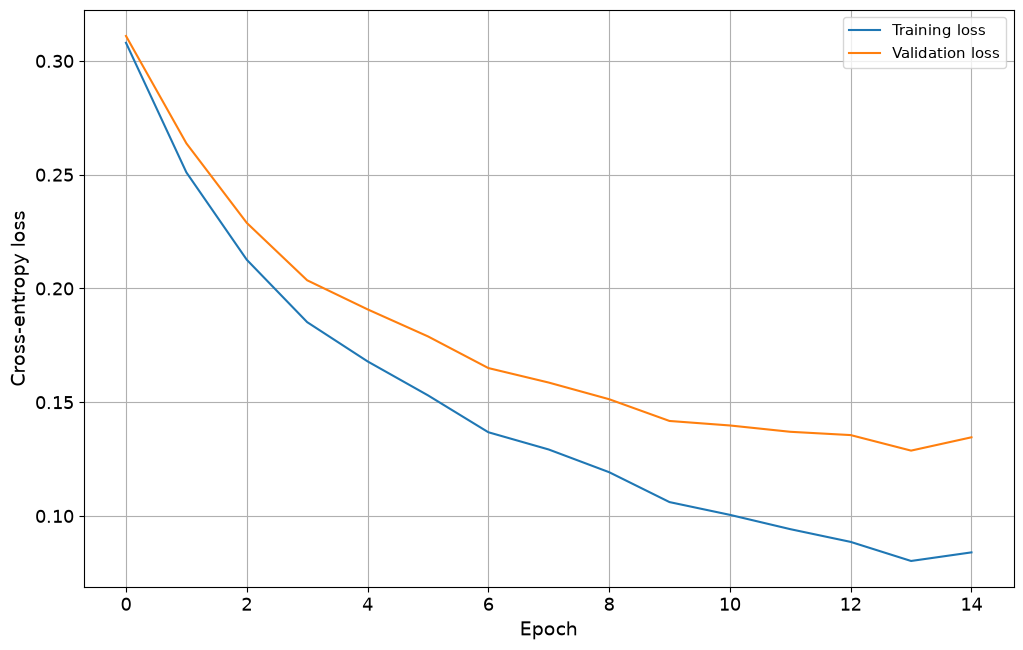

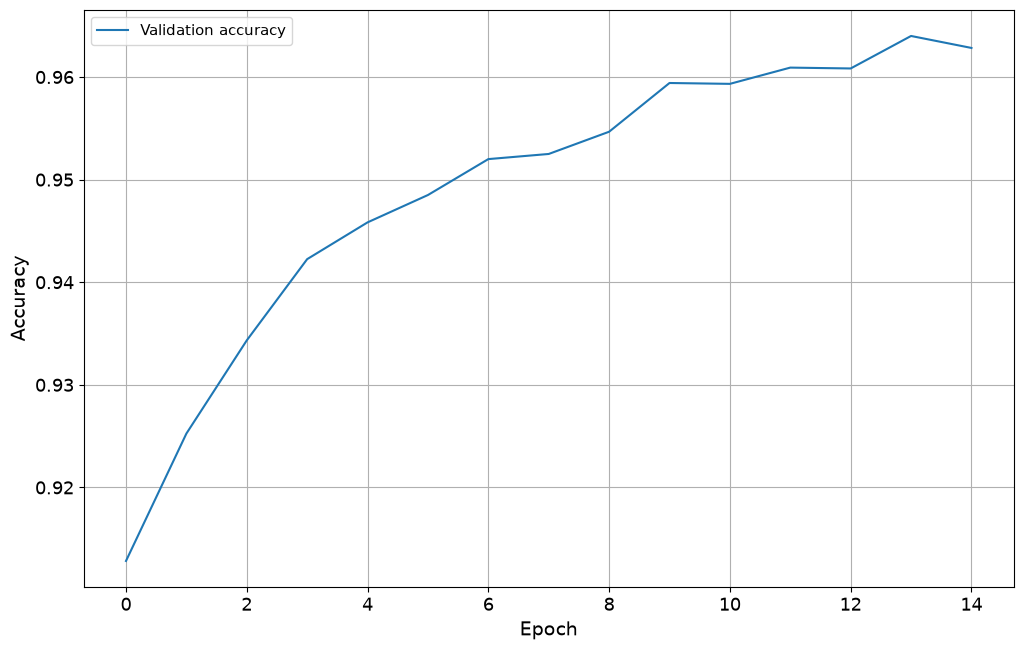

In [20]:
# Plot training and validation loss
plt.figure(figsize=(12, 7.5))
plt.plot(history["train_loss"], label="Training loss")
plt.plot(history["val_loss"], label="Validation loss")
plt.xlabel("Epoch", fontsize=label_fontsize)
plt.ylabel("Cross-entropy loss", fontsize=label_fontsize)
# plt.title("Training and validation loss", fontsize=title_fontsize)
plt.tick_params(axis="both", which="both", labelsize=tick_fontsize)
plt.legend(fontsize=legend_fontsize)
plt.grid()
plt.show()

# Plot validation accuracy
plt.figure(figsize=(12, 7.5))
plt.plot(history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epoch", fontsize=label_fontsize)
plt.ylabel("Accuracy", fontsize=label_fontsize)
# plt.title("Validation accuracy during training", fontsize=title_fontsize)
plt.tick_params(axis="both", which="both", labelsize=tick_fontsize)
plt.legend(fontsize=legend_fontsize)
plt.grid()
plt.show()

In [21]:
# Make predictions on the official test images
test_predict = feed_forward_batch(
    X_test,
    layers,
    activation_funcs
)

# Calculate final test accuracy
test_accuracy = accuracy(test_predict, y_test)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test accuracy in percent: {test_accuracy * 100:.2f}%")

Test accuracy: 0.9633
Test accuracy in percent: 96.33%


In [22]:
#So up until this point it's the first bit of part e, now i will look at diff models and hyperparameters
# First establishing logistic regression baseline

# Create a network with no hidden layers
logistic_layers = init_layers_zero_bias([784, 10], seed=2026)

# Only one activation function: softmax at the output
logistic_activation_funcs = [softmax]

# Train the logistic regression model
logistic_layers, logistic_history = train_classifier(
    logistic_layers,
    X_fit,
    Y_fit,
    X_val,
    y_val,
    logistic_activation_funcs,
    [],                  # No hidden layers, so no hidden activation derivatives
    gamma=0.001,
    epochs=15,
    batch_size=128,
    method="adam"
)

Epoch 1/15 | Training loss: 0.4281 | Validation loss: 0.4284 | Validation accuracy: 0.8913
Epoch 2/15 | Training loss: 0.3506 | Validation loss: 0.3562 | Validation accuracy: 0.9063
Epoch 3/15 | Training loss: 0.3161 | Validation loss: 0.3219 | Validation accuracy: 0.9138
Epoch 4/15 | Training loss: 0.2992 | Validation loss: 0.3076 | Validation accuracy: 0.9149
Epoch 5/15 | Training loss: 0.2875 | Validation loss: 0.2989 | Validation accuracy: 0.9187
Epoch 6/15 | Training loss: 0.2805 | Validation loss: 0.2930 | Validation accuracy: 0.9215
Epoch 7/15 | Training loss: 0.2733 | Validation loss: 0.2887 | Validation accuracy: 0.9217
Epoch 8/15 | Training loss: 0.2681 | Validation loss: 0.2852 | Validation accuracy: 0.9204
Epoch 9/15 | Training loss: 0.2651 | Validation loss: 0.2833 | Validation accuracy: 0.9215
Epoch 10/15 | Training loss: 0.2612 | Validation loss: 0.2831 | Validation accuracy: 0.9234
Epoch 11/15 | Training loss: 0.2575 | Validation loss: 0.2794 | Validation accuracy: 0.92

In [23]:
# Get the final validation accuracy of each model
logistic_accuracy = logistic_history["val_accuracy"][-1]
nn_accuracy = history["val_accuracy"][-1]

print(f"Logistic regression validation accuracy: {logistic_accuracy:.4f}")
print(f"Neural network validation accuracy:     {nn_accuracy:.4f}")

print(f"\nLogistic regression: {logistic_accuracy * 100:.2f}%")
print(f"Neural network:      {nn_accuracy * 100:.2f}%")

Logistic regression validation accuracy: 0.9261
Neural network validation accuracy:     0.9628

Logistic regression: 92.61%
Neural network:      96.28%


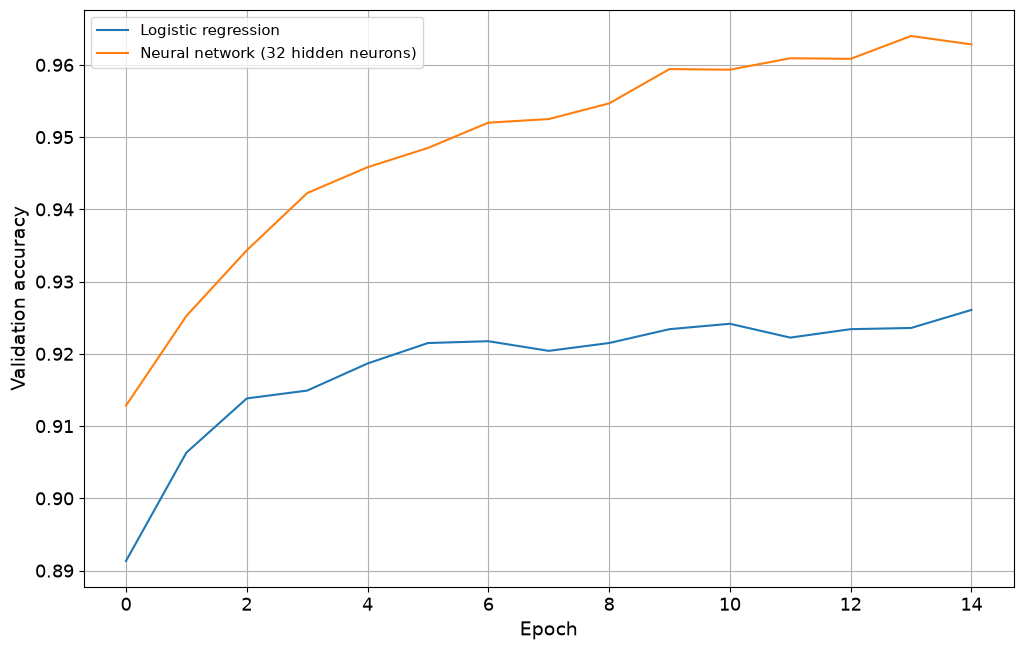

In [24]:
plt.figure(figsize=(12, 7.5))

plt.plot(
    logistic_history["val_accuracy"],
    label="Logistic regression"
)

plt.plot(
    history["val_accuracy"],
    label="Neural network (32 hidden neurons)"
)

plt.xlabel("Epoch", fontsize=label_fontsize)
plt.ylabel("Validation accuracy", fontsize=label_fontsize)
# plt.title("Logistic regression vs neural network", fontsize=title_fontsize)
plt.tick_params(axis="both", which="both", labelsize=tick_fontsize)
plt.legend(fontsize=legend_fontsize)
plt.grid()
plt.show()

In [25]:
# Experimenting with architectures in order to compare no hidden layer vs one hidden layer vs multiple hidden layers
architectures = {
    "32 neurons": [784, 32, 10],
    "64 neurons": [784, 64, 10],
    "128 neurons": [784, 128, 10],
    "Two hidden layers": [784, 64, 32, 10]
}

architecture_results = {}

for name, sizes in architectures.items():

    print(f"\nTraining: {name}")

    layers_new = init_layers_zero_bias(sizes, seed=2026)

# ReLU for every hidden layer, softmax for the output
    activation_funcs_new = [ReLU] * (len(sizes) - 2) + [softmax]

# Derivatives are only needed for hidden layers
    activation_ders_new = [ReLU_der] * (len(sizes) - 2)

    trained_layers, history_new = train_classifier(
        layers_new,
        X_fit, Y_fit,
        X_val, y_val,
        activation_funcs_new,
        activation_ders_new,
        gamma=0.001,
        epochs=15,
        batch_size=128,
        method="adam",
        seed=2026
    )

    architecture_results[name] = {
        "layers": trained_layers,
        "history": history_new,
        "activation_funcs": activation_funcs_new,
        "activation_ders": activation_ders_new
    }


Training: 32 neurons
Epoch 1/15 | Training loss: 0.3080 | Validation loss: 0.3110 | Validation accuracy: 0.9128
Epoch 2/15 | Training loss: 0.2510 | Validation loss: 0.2638 | Validation accuracy: 0.9253
Epoch 3/15 | Training loss: 0.2126 | Validation loss: 0.2288 | Validation accuracy: 0.9343
Epoch 4/15 | Training loss: 0.1852 | Validation loss: 0.2036 | Validation accuracy: 0.9423
Epoch 5/15 | Training loss: 0.1679 | Validation loss: 0.1908 | Validation accuracy: 0.9458
Epoch 6/15 | Training loss: 0.1530 | Validation loss: 0.1789 | Validation accuracy: 0.9485
Epoch 7/15 | Training loss: 0.1368 | Validation loss: 0.1650 | Validation accuracy: 0.9520
Epoch 8/15 | Training loss: 0.1292 | Validation loss: 0.1586 | Validation accuracy: 0.9525
Epoch 9/15 | Training loss: 0.1192 | Validation loss: 0.1513 | Validation accuracy: 0.9547
Epoch 10/15 | Training loss: 0.1061 | Validation loss: 0.1418 | Validation accuracy: 0.9594
Epoch 11/15 | Training loss: 0.1005 | Validation loss: 0.1398 | Val

In [26]:
print(f"{'Model':<25} {'Best validation accuracy':>25}")

# Existing logistic regression
print(
    f"{'Logistic regression':<25}"
    f"{max(logistic_history['val_accuracy']):>25.4f}"
)

for name, result in architecture_results.items():

    best_accuracy = max(result["history"]["val_accuracy"])

    print(f"{name:<25}{best_accuracy:>25.4f}")

Model                      Best validation accuracy
Logistic regression                         0.9261
32 neurons                                  0.9640
64 neurons                                  0.9717
128 neurons                                 0.9751
Two hidden layers                           0.9712


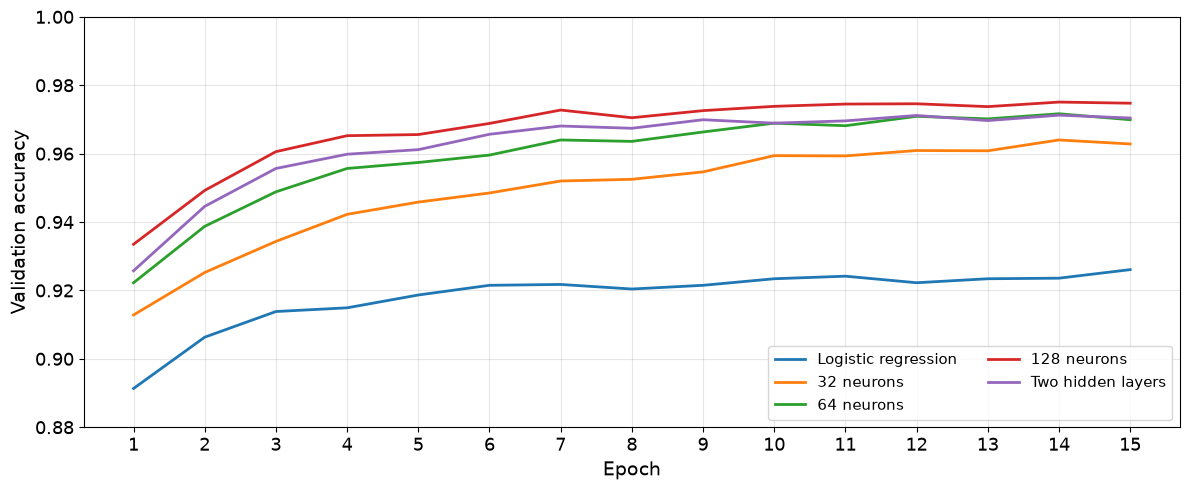

In [51]:
plt.figure(figsize=(12, 5))

# Logistic regression
plt.plot(
    np.arange(1, len(logistic_history["val_accuracy"]) + 1),
    logistic_history["val_accuracy"],
    label="Logistic regression",
    linewidth=2
)

# All neural network architectures
for name, result in architecture_results.items():

    accuracy_values = result["history"]["val_accuracy"]

    plt.plot(
        np.arange(1, len(accuracy_values) + 1),
        accuracy_values,
        label=name,
        linewidth=2
    )

plt.xlabel("Epoch",fontsize=label_fontsize)
plt.ylabel("Validation accuracy",fontsize=label_fontsize)
# plt.title("Validation accuracy for different network architectures",fontsize=title_fontsize)

plt.xticks(range(1, 16))
plt.ylim(0.88, 1.00)
plt.tick_params(axis="both",which="both",labelsize=tick_fontsize)

plt.legend(loc="lower right",fontsize=legend_fontsize, ncol=2)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("./figures/parte_val_acc_architectures.png", dpi=500, bbox_inches="tight")
plt.show()

In [28]:
# Asctivation comparison section

activation_experiments = {
    "ReLU": (ReLU, ReLU_der),
    "Leaky ReLU": (leaky_ReLU, leaky_ReLU_der),
    "Sigmoid": (sigmoid, sigmoid_der)
}

activation_results = {}

for name, (activation, derivative) in activation_experiments.items():

    print(f"\nTraining with {name}")

# Initialise a fresh network with the same architecture
    layers_new = init_layers_zero_bias([784, 128, 10], seed=2026)

# Hidden layer uses the chosen activation.
# Output layer always uses softmax.
    activation_funcs_new = [activation, softmax]
    activation_ders_new = [derivative]

    trained_layers, history_new = train_classifier(
        layers_new,
        X_fit, Y_fit,
        X_val, y_val,
        activation_funcs_new,
        activation_ders_new,
        gamma=0.001,
        epochs=15,
        batch_size=128,
        method="adam",
        seed=2026
    )

    activation_results[name] = {
        "layers": trained_layers,
        "history": history_new,
        "activation_funcs": activation_funcs_new,
        "activation_ders": activation_ders_new
    }


Training with ReLU
Epoch 1/15 | Training loss: 0.2261 | Validation loss: 0.2343 | Validation accuracy: 0.9335
Epoch 2/15 | Training loss: 0.1591 | Validation loss: 0.1772 | Validation accuracy: 0.9493
Epoch 3/15 | Training loss: 0.1186 | Validation loss: 0.1423 | Validation accuracy: 0.9606
Epoch 4/15 | Training loss: 0.0897 | Validation loss: 0.1205 | Validation accuracy: 0.9653
Epoch 5/15 | Training loss: 0.0815 | Validation loss: 0.1180 | Validation accuracy: 0.9656
Epoch 6/15 | Training loss: 0.0643 | Validation loss: 0.1048 | Validation accuracy: 0.9688
Epoch 7/15 | Training loss: 0.0517 | Validation loss: 0.0948 | Validation accuracy: 0.9728
Epoch 8/15 | Training loss: 0.0484 | Validation loss: 0.0983 | Validation accuracy: 0.9705
Epoch 9/15 | Training loss: 0.0405 | Validation loss: 0.0923 | Validation accuracy: 0.9726
Epoch 10/15 | Training loss: 0.0304 | Validation loss: 0.0889 | Validation accuracy: 0.9738
Epoch 11/15 | Training loss: 0.0262 | Validation loss: 0.0869 | Valid

In [29]:
print("Activation function comparison")
print("--------------------------------")

print(f"{'Activation':<20} {'Best val. accuracy':>20}")

for name, result in activation_results.items():

    best_accuracy = max(result["history"]["val_accuracy"])

    print(f"{name:<20} {best_accuracy:>20.4f}")

Activation function comparison
--------------------------------
Activation             Best val. accuracy
ReLU                               0.9751
Leaky ReLU                         0.9750
Sigmoid                            0.9708


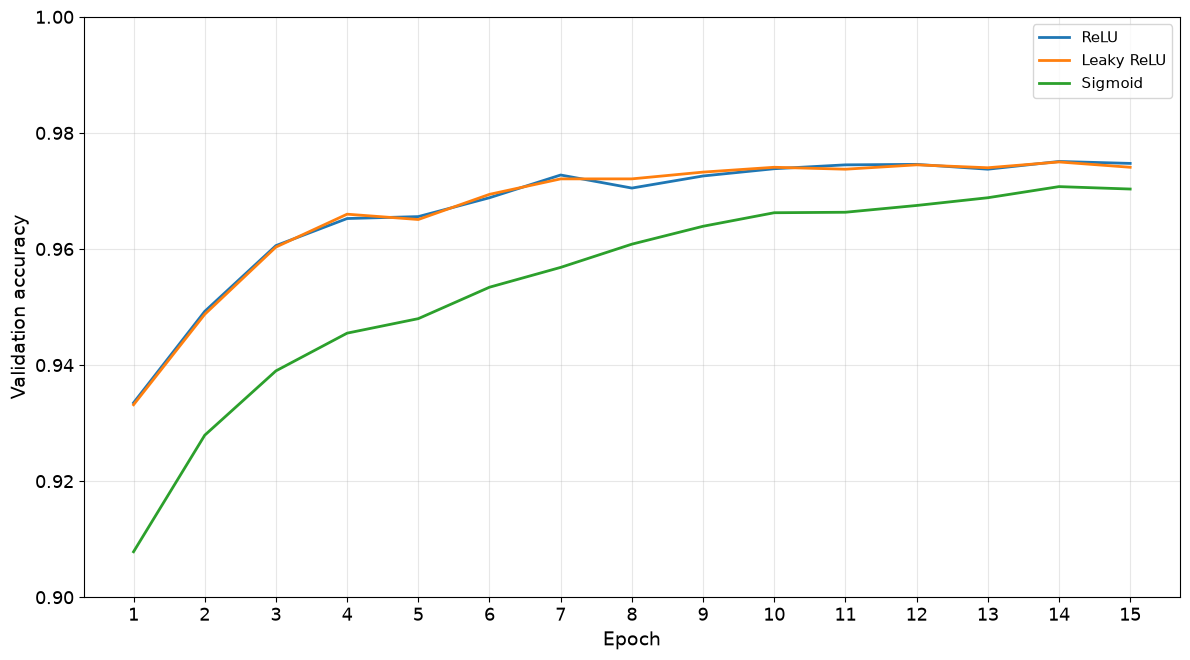

In [30]:
plt.figure(figsize=(12, 6.7))

for name, result in activation_results.items():

    values = result["history"]["val_accuracy"]

    plt.plot(
        range(1, len(values) + 1),
        values,
        label=name,
        linewidth=2
    )

plt.xlabel("Epoch", fontsize=label_fontsize)
plt.ylabel("Validation accuracy", fontsize=label_fontsize)
# plt.title("Effect of activation function on classification accuracy", fontsize=title_fontsize)
plt.xticks(range(1, 16))
plt.ylim(0.90, 1.00)
plt.tick_params(axis="both", which="both", labelsize=tick_fontsize)
plt.legend(fontsize=legend_fontsize)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

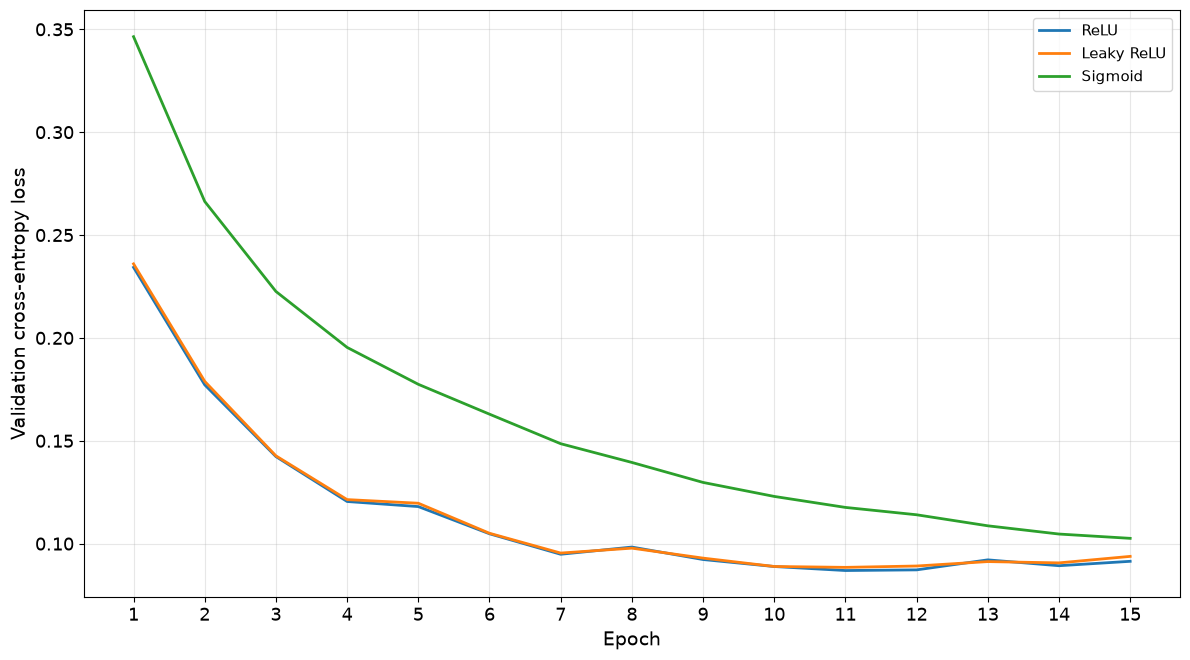

In [31]:
plt.figure(figsize=(12, 6.7))

for name, result in activation_results.items():

    values = result["history"]["val_loss"]

    plt.plot(
        range(1, len(values) + 1),
        values,
        label=name,
        linewidth=2
    )

plt.xlabel("Epoch", fontsize=label_fontsize)
plt.ylabel("Validation cross-entropy loss", fontsize=label_fontsize)
# plt.title("Validation loss for different activation functions", fontsize=title_fontsize)
plt.xticks(range(1, 16))
plt.tick_params(axis="both", which="both", labelsize=tick_fontsize)
plt.legend(fontsize=legend_fontsize)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [32]:
gammas = [
    0.0001, 0.0002, 0.0005,
    0.001, 0.002, 0.005,
    0.01, 0.02, 0.05, 0.1, 0.5
]

grid_gammas = {}
grid_se = {}
grid_accuracy = {}

# Loop over the different learning rates
for gamma in gammas:

    mean, se, mean_accuracy = cv_classifier(
        X_fit, y_fit,
        gamma=gamma,
        k=5,
        epochs=15,
        batch_size=128
    )

    grid_gammas[gamma] = mean
    grid_se[gamma] = se
    grid_accuracy[gamma] = mean_accuracy

    print(
        f"Learning rate {gamma}: "
        f"CV cross-entropy = {mean:.4f} "
        f"+/- {se:.4f}, "
        f"CV accuracy = {mean_accuracy:.4f}"
    )

Epoch 1/15 | Training loss: 0.7079 | Validation loss: 0.7266 | Validation accuracy: 0.8422
Epoch 2/15 | Training loss: 0.4530 | Validation loss: 0.4705 | Validation accuracy: 0.8794
Epoch 3/15 | Training loss: 0.3693 | Validation loss: 0.3859 | Validation accuracy: 0.8945
Epoch 4/15 | Training loss: 0.3254 | Validation loss: 0.3426 | Validation accuracy: 0.9058
Epoch 5/15 | Training loss: 0.2973 | Validation loss: 0.3159 | Validation accuracy: 0.9119
Epoch 6/15 | Training loss: 0.2777 | Validation loss: 0.2973 | Validation accuracy: 0.9155
Epoch 7/15 | Training loss: 0.2618 | Validation loss: 0.2832 | Validation accuracy: 0.9187
Epoch 8/15 | Training loss: 0.2486 | Validation loss: 0.2689 | Validation accuracy: 0.9248
Epoch 9/15 | Training loss: 0.2362 | Validation loss: 0.2590 | Validation accuracy: 0.9257
Epoch 10/15 | Training loss: 0.2267 | Validation loss: 0.2498 | Validation accuracy: 0.9287
Epoch 11/15 | Training loss: 0.2170 | Validation loss: 0.2421 | Validation accuracy: 0.93

Lowest CV cross-entropy:
Learning rate: 0.001
Mean CV cross-entropy: 0.0952

Learning rates within one standard error:
[0.001]

Selected learning rate using the one-standard-error rule:
0.001


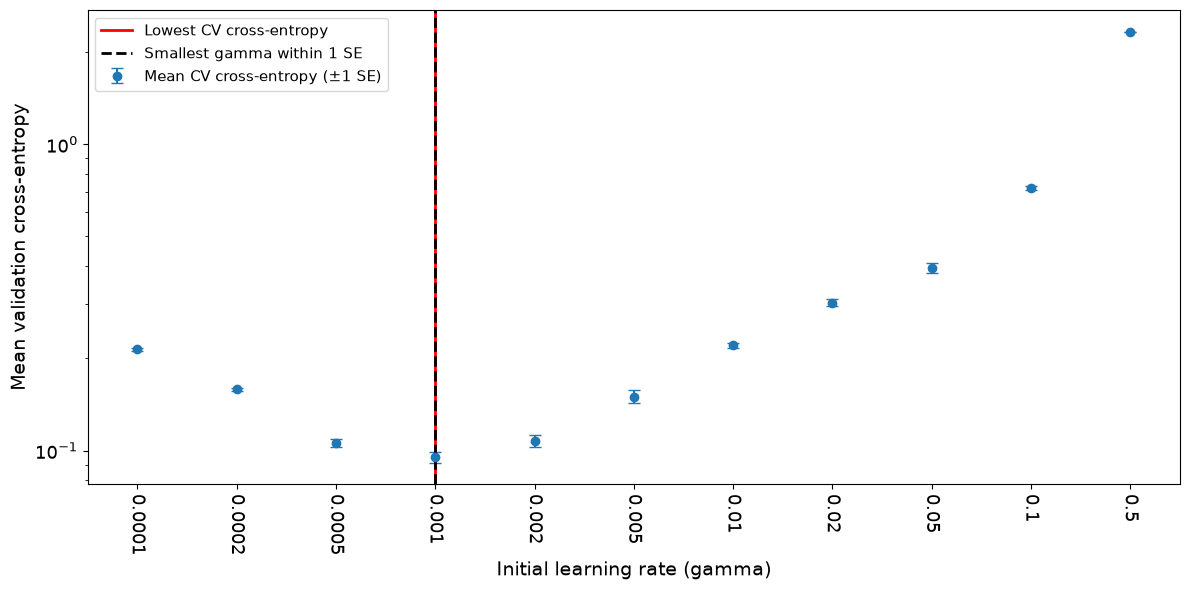

In [33]:
# Convert results into arrays for plotting
mean_losses = np.array([grid_gammas[g] for g in gammas])
standard_errors = np.array([grid_se[g] for g in gammas])
mean_accuracies = np.array([grid_accuracy[g] for g in gammas])

# Find the learning rate with the lowest mean CV cross-entropy
i_best = np.argmin(mean_losses)

# Calculate the one-standard-error threshold
threshold = mean_losses[i_best] + standard_errors[i_best]

# Find learning rates within one standard error of the minimum
within = mean_losses <= threshold

# Select the smallest learning rate within one standard error
selected_gamma = np.array(gammas)[within].min()

print("Lowest CV cross-entropy:")
print(f"Learning rate: {gammas[i_best]}")
print(f"Mean CV cross-entropy: {mean_losses[i_best]:.4f}")

print("\nLearning rates within one standard error:")
print(np.array(gammas)[within])

print("\nSelected learning rate using the one-standard-error rule:")
print(selected_gamma)

# Plot cross-validation cross-entropy
fig, ax = plt.subplots(figsize=(12, 6))

ax.errorbar(
    np.arange(len(gammas)),
    mean_losses,
    yerr=standard_errors,
    fmt="o",
    capsize=4,
    label="Mean CV cross-entropy (±1 SE)"
)

# Mark the absolute minimum
ax.axvline(
    i_best,
    color="red",
    linewidth=2,
    label="Lowest CV cross-entropy"
)

# Mark the selected learning rate
selected_index = gammas.index(selected_gamma)

ax.axvline(
    selected_index,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Smallest gamma within 1 SE"
)

ax.set_xticks(np.arange(len(gammas)))
ax.set_xticklabels(gammas, rotation=270)

ax.set_xlabel("Initial learning rate (gamma)", fontsize=label_fontsize)
ax.set_ylabel("Mean validation cross-entropy", fontsize=label_fontsize)
# ax.set_title("5-fold cross-validation: learning rate selection")

ax.set_yscale("log")
ax.tick_params(axis="both", which="both", labelsize=tick_fontsize)
ax.legend(fontsize=legend_fontsize)
plt.tight_layout()
plt.show()

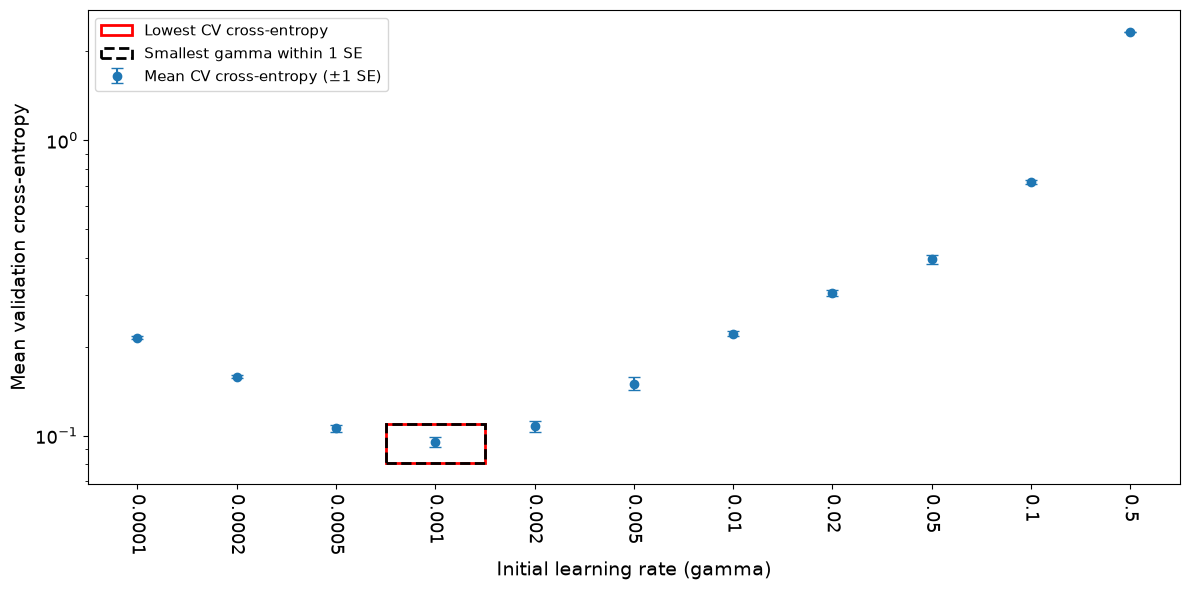

In [34]:
# Plot cross-validation cross-entropy
fig, ax = plt.subplots(figsize=(12, 6))

ax.errorbar(
    np.arange(len(gammas)),
    mean_losses,
    yerr=standard_errors,
    fmt="o",
    capsize=4,
    label="Mean CV cross-entropy (±1 SE)"
)

# Mark the absolute minimum
ax.add_patch(plt.Rectangle(
    (i_best - 0.5, mean_losses[i_best] * 0.85),
    1,
    mean_losses[i_best] * 0.3,
    fill=False,
    edgecolor="red",
    lw=2,
    label="Lowest CV cross-entropy"
))

# Mark the selected learning rate
selected_index = gammas.index(selected_gamma)

ax.add_patch(plt.Rectangle(
    (selected_index - 0.5, mean_losses[selected_index] * 0.85),
    1,
    mean_losses[selected_index] * 0.3,
    fill=False,
    edgecolor="black",
    lw=2,
    linestyle="--",
    label="Smallest gamma within 1 SE"
))

ax.set_xticks(np.arange(len(gammas)))
ax.set_xticklabels(gammas, rotation=270)

ax.set_xlabel("Initial learning rate (gamma)", fontsize=label_fontsize)
ax.set_ylabel("Mean validation cross-entropy", fontsize=label_fontsize)
# ax.set_title("5-fold cross-validation: learning rate selection")

ax.set_yscale("log")
ax.tick_params(axis="both", which="both", labelsize=tick_fontsize)
ax.legend(fontsize=legend_fontsize)
plt.tight_layout()
plt.savefig("./figures/parte_cv_learning_rate.png", dpi=500, bbox_inches="tight")
plt.show()
plt.show()

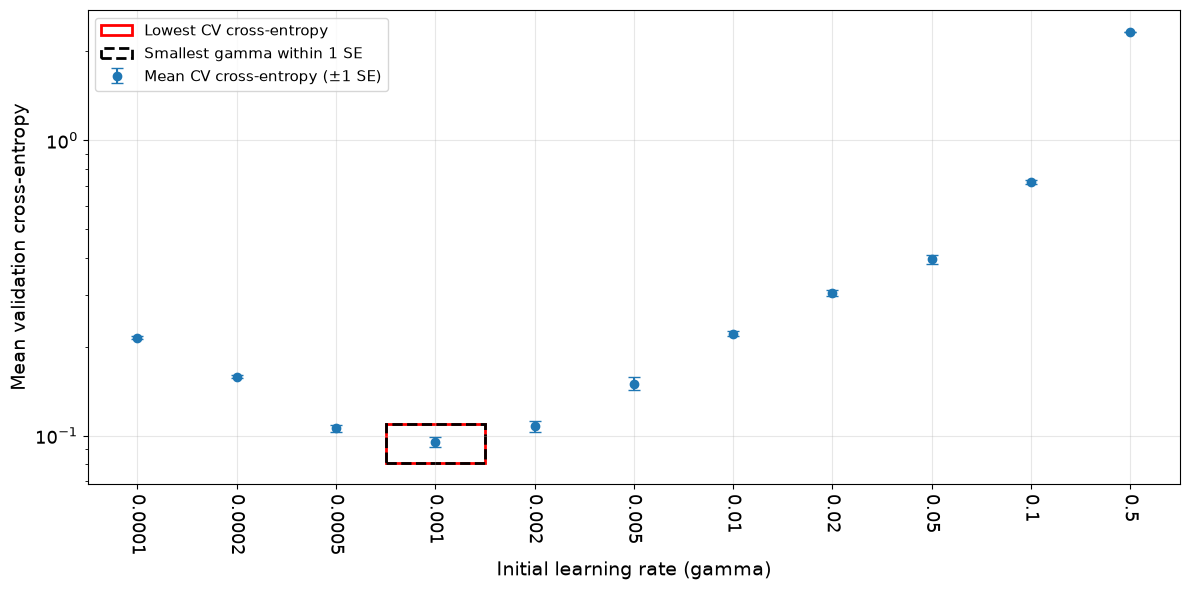

In [35]:
# Plot cross-validation cross-entropy
fig, ax = plt.subplots(figsize=(12, 6))

ax.errorbar(
    np.arange(len(gammas)),
    mean_losses,
    yerr=standard_errors,
    fmt="o",
    capsize=4,
    label="Mean CV cross-entropy (±1 SE)"
)

# Mark the absolute minimum
ax.add_patch(plt.Rectangle(
    (i_best - 0.5, mean_losses[i_best] * 0.85),
    1,
    mean_losses[i_best] * 0.3,
    fill=False,
    edgecolor="red",
    lw=2,
    label="Lowest CV cross-entropy"
))

# Mark the selected learning rate
selected_index = gammas.index(selected_gamma)

ax.add_patch(plt.Rectangle(
    (selected_index - 0.5, mean_losses[selected_index] * 0.85),
    1,
    mean_losses[selected_index] * 0.3,
    fill=False,
    edgecolor="black",
    lw=2,
    linestyle="--",
    label="Smallest gamma within 1 SE"
))

# Formatting
ax.set_xticks(np.arange(len(gammas)))
ax.set_xticklabels(gammas, rotation=270, fontsize=tick_fontsize)

ax.set_xlabel("Initial learning rate (gamma)", fontsize=label_fontsize)
ax.set_ylabel("Mean validation cross-entropy", fontsize=label_fontsize)
# ax.set_title("5-fold cross-validation: learning rate selection", fontsize=title_fontsize)

ax.set_yscale("log")
ax.tick_params(axis="both", which="both", labelsize=tick_fontsize)

ax.legend(fontsize=legend_fontsize)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("./figures/parte_cv_learning_rate.png", dpi=500, bbox_inches="tight")
plt.show()

In [36]:
print("Learning rate comparison")
print("-" * 75)
print(f"{'Gamma':<12}{'CV cross-entropy':<22}{'Standard error':<20}{'CV accuracy'}")

for gamma in gammas:
    print(
        f"{gamma:<12}"
        f"{grid_gammas[gamma]:<22.5f}"
        f"{grid_se[gamma]:<20.5f}"
        f"{grid_accuracy[gamma]:.4f}"
    )

print("\nSelected gamma:", selected_gamma)

Learning rate comparison
---------------------------------------------------------------------------
Gamma       CV cross-entropy      Standard error      CV accuracy
0.0001      0.21405               0.00262             0.9389
0.0002      0.15835               0.00213             0.9536
0.0005      0.10600               0.00290             0.9677
0.001       0.09519               0.00390             0.9718
0.002       0.10760               0.00454             0.9721
0.005       0.15002               0.00754             0.9714
0.01        0.22103               0.00409             0.9672
0.02        0.30406               0.00744             0.9575
0.05        0.39458               0.01444             0.9263
0.1         0.71929               0.01125             0.8407
0.5         2.32801               0.00388             0.1009

Selected gamma: 0.001


In [37]:
# Lambda values to investigate
lambdas = [0, 0.00001, 0.0001, 0.001, 0.01, 0.1]

# Use the learning rate selected in the previous experiment
gamma_for_regularisation = selected_gamma

regularisation_results = {}

for lam in lambdas:

    print(f"\nTraining with lambda = {lam}")

# Initialise a fresh network for each lambda
    layers_new = init_layers_zero_bias([784, 128, 10], seed=2026)

    activation_funcs_new = [ReLU, softmax]
    activation_ders_new = [ReLU_der]

    trained_layers, history_new = train_classifier_l2(
        layers_new,
        X_fit,
        Y_fit,
        X_val,
        y_val,
        activation_funcs_new,
        activation_ders_new,
        gamma=gamma_for_regularisation,
        lam=lam,
        epochs=15,
        batch_size=128,
        method="adam",
        seed=2026
    )

    regularisation_results[lam] = {
        "layers": trained_layers,
        "history": history_new,
        "activation_funcs": activation_funcs_new,
        "activation_ders": activation_ders_new
    }


Training with lambda = 0
Epoch 1/15 | Training loss: 0.2261 | Validation loss: 0.2343 | Validation accuracy: 0.9335
Epoch 2/15 | Training loss: 0.1591 | Validation loss: 0.1772 | Validation accuracy: 0.9493
Epoch 3/15 | Training loss: 0.1186 | Validation loss: 0.1423 | Validation accuracy: 0.9606
Epoch 4/15 | Training loss: 0.0897 | Validation loss: 0.1205 | Validation accuracy: 0.9653
Epoch 5/15 | Training loss: 0.0815 | Validation loss: 0.1180 | Validation accuracy: 0.9656
Epoch 6/15 | Training loss: 0.0643 | Validation loss: 0.1048 | Validation accuracy: 0.9688
Epoch 7/15 | Training loss: 0.0517 | Validation loss: 0.0948 | Validation accuracy: 0.9728
Epoch 8/15 | Training loss: 0.0484 | Validation loss: 0.0983 | Validation accuracy: 0.9705
Epoch 9/15 | Training loss: 0.0405 | Validation loss: 0.0923 | Validation accuracy: 0.9726
Epoch 10/15 | Training loss: 0.0304 | Validation loss: 0.0889 | Validation accuracy: 0.9738
Epoch 11/15 | Training loss: 0.0262 | Validation loss: 0.0869 |

Lambda           Best val. accuracy    Lowest val. loss
0                            0.9751              0.0869
1e-05                        0.9752              0.0866
0.0001                       0.9751              0.0836
0.001                        0.9733              0.1011
0.01                         0.9364              0.2635
0.1                          0.8520              0.8172


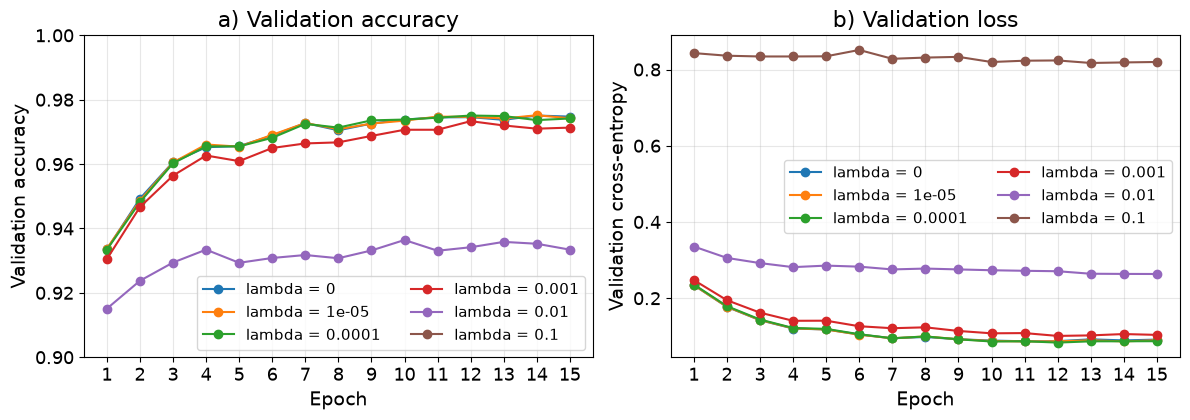

In [38]:
#L2 regularisation comparison

print(
    f"{'Lambda':<15}"
    f"{'Best val. accuracy':>20}"
    f"{'Lowest val. loss':>20}"
)

for lam, result in regularisation_results.items():

    best_accuracy = max(result["history"]["val_accuracy"])
    best_loss = min(result["history"]["val_loss"])

    print(
        f"{lam:<15}"
        f"{best_accuracy:>20.4f}"
        f"{best_loss:>20.4f}"
    )

# Plot validation accuracy and cross-entropy side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))

# Plot validation accuracy
for lam, result in regularisation_results.items():

    axes[0].plot(
        range(1, 16),
        result["history"]["val_accuracy"],
        marker="o",
        label=f"lambda = {lam}"
    )

axes[0].set_xlabel("Epoch", fontsize=label_fontsize)
axes[0].set_ylabel("Validation accuracy", fontsize=label_fontsize)
# original title: "Effect of L2 regularisation on validation accuracy"
axes[0].set_title("a) Validation accuracy", fontsize=title_fontsize)

axes[0].set_xticks(range(1, 16))
axes[0].set_ylim(0.90, 1.00)
axes[0].tick_params(axis="both", which="both", labelsize=tick_fontsize)
axes[0].legend(fontsize=legend_fontsize, ncol=2)
axes[0].grid(alpha=0.3)

# Plot validation cross-entropy
for lam, result in regularisation_results.items():

    axes[1].plot(
        range(1, 16),
        result["history"]["val_loss"],
        marker="o",
        label=f"lambda = {lam}"
    )

axes[1].set_xlabel("Epoch", fontsize=label_fontsize)
axes[1].set_ylabel("Validation cross-entropy", fontsize=label_fontsize)
# original title: "Effect of L2 regularisation on validation loss"
axes[1].set_title("b) Validation loss", fontsize=title_fontsize)

axes[1].set_xticks(range(1, 16))
axes[1].tick_params(axis="both", which="both", labelsize=tick_fontsize)
axes[1].legend(fontsize=legend_fontsize, ncol=2)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("./figures/parte_l2_regularisation.png", dpi=500, bbox_inches="tight")
plt.show()

In [39]:
# Select the model with lambda = 0.0001
best_model = regularisation_results[0.0001]

# Generate predictions for the test set
test_predictions = feed_forward_batch(
    X_test,
    best_model["layers"],
    best_model["activation_funcs"]
)

# Calculate test cross-entropy and accuracy
test_loss = cross_entropy(test_predictions, one_hot(y_test))
test_accuracy = accuracy(test_predictions, y_test)

print(f"Test cross-entropy: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")

Test cross-entropy: 0.0751
Test accuracy: 0.9768


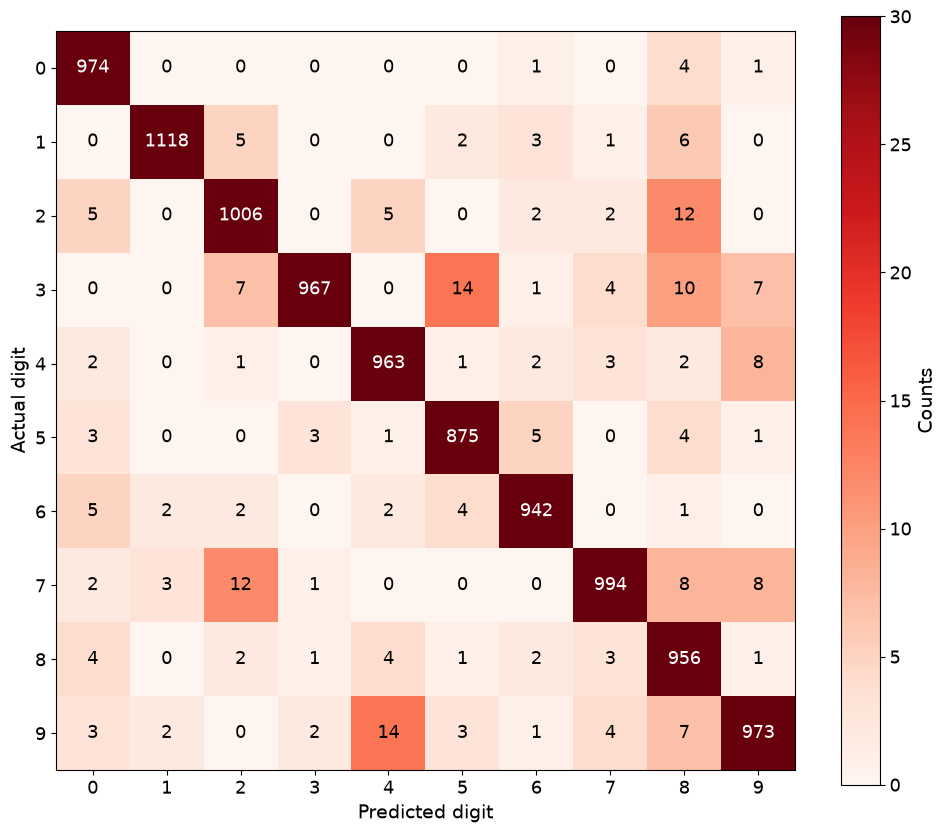

In [49]:
# Convert predicted probabilities into predicted digits
y_pred = np.argmax(np.asarray(test_predictions), axis=1)

# Calculate confusion matrix
Cm = confusion_matrix(y_test, y_pred)

# Plot confusion matrix
fig, ax = plt.subplots(figsize=(10, 9))

im = ax.imshow(Cm, cmap="Reds", vmin=0, vmax=30)

# Write the number of images in each square
for i in range(10):
    for j in range(10):
        ax.text(
            j, i, str(Cm[i, j]),
            ha="center",
            va="center",
            fontsize=tick_fontsize,
            color="white" if Cm[i, j] > Cm.max() * 0.5 else "black"
        )

# Axis formatting
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("Predicted digit", fontsize=label_fontsize)
ax.set_ylabel("Actual digit", fontsize=label_fontsize)
# ax.set_title("Confusion matrix: MNIST neural network", fontsize=title_fontsize)

ax.tick_params(axis="both", which="both", labelsize=tick_fontsize)

# Colour bar
cbar = plt.colorbar(im, ax=ax, shrink=0.9)
cbar.ax.tick_params(labelsize=tick_fontsize)
cbar.set_label("Counts", fontsize=label_fontsize)

plt.tight_layout()
plt.savefig("./figures/parte_confusion_matrix.png", dpi=500, bbox_inches="tight")
plt.show()

In [41]:
print("Classification report:\n")

print(classification_report(
    y_test,
    y_pred,
    digits=4
))

Classification report:

              precision    recall  f1-score   support

           0     0.9760    0.9939    0.9848       980
           1     0.9938    0.9850    0.9894      1135
           2     0.9720    0.9748    0.9734      1032
           3     0.9928    0.9574    0.9748      1010
           4     0.9737    0.9807    0.9772       982
           5     0.9722    0.9809    0.9766       892
           6     0.9823    0.9833    0.9828       958
           7     0.9832    0.9669    0.9750      1028
           8     0.9465    0.9815    0.9637       974
           9     0.9740    0.9643    0.9691      1009

    accuracy                         0.9768     10000
   macro avg     0.9766    0.9769    0.9767     10000
weighted avg     0.9770    0.9768    0.9768     10000



In [42]:
# Comparison against an established machine-learning implementation, in this case scikitlearn

# Initialise logistic regression
sklearn_logistic = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    random_state=2026
)

# Train on the full MNIST training set
sklearn_logistic.fit(X_train, y_train)

# Predict the test set
sklearn_predictions = sklearn_logistic.predict(X_test)
sklearn_probabilities = sklearn_logistic.predict_proba(X_test)

# Evaluate performance
sklearn_accuracy = accuracy_score(y_test, sklearn_predictions)
sklearn_loss = log_loss(y_test, sklearn_probabilities)

print(f"Scikit-Learn test accuracy: {sklearn_accuracy:.4f}")
print(f"Scikit-Learn test cross-entropy: {sklearn_loss:.4f}")

Scikit-Learn test accuracy: 0.9258
Scikit-Learn test cross-entropy: 0.2720


In [43]:
# Predict using our own logistic regression model
own_logistic_predictions = feed_forward_batch(
    X_test,
    logistic_layers,
    logistic_activation_funcs
)

# Calculate test accuracy and cross-entropy
own_logistic_accuracy = accuracy(
    own_logistic_predictions, y_test
)

own_logistic_loss = cross_entropy(
    own_logistic_predictions, one_hot(y_test)
)

print(f"Our logistic regression test accuracy: {own_logistic_accuracy:.4f}")
print(f"Our logistic regression test cross-entropy: {own_logistic_loss:.4f}")

Our logistic regression test accuracy: 0.9265
Our logistic regression test cross-entropy: 0.2659
